In [1]:
import os
import glob
import pandas as pd
import numpy as np
from datetime import datetime
from math import radians, sin, cos, sqrt, atan2

In [2]:
BASE_DIR = r"C:\Users\suzak\Desktop\thesis\bike data"

all_files = sorted(glob.glob(os.path.join(BASE_DIR, "dublinbikes_20*")))

print(f"Found {len(all_files)} files:")
for f in all_files:
    print(os.path.basename(f))

Found 16 files:
dublinbikes_20240501.csv
dublinbikes_20240601.csv
dublinbikes_20240701.csv
dublinbikes_20240801.csv
dublinbikes_20240901.csv
dublinbikes_20241001.csv
dublinbikes_20241101.csv
dublinbikes_20241201.csv
dublinbikes_20250101.csv
dublinbikes_20250201.csv
dublinbikes_20250301.csv
dublinbikes_20250401.csv
dublinbikes_20250501.csv
dublinbikes_20250601.csv
dublinbikes_20250701.csv
dublinbikes_20250801.csv


In [3]:
def extract_date_from_filename(path):
    name = os.path.basename(path)
    date_str = name.split("_")[1][:8]  # YYYYMMDD
    return datetime.strptime(date_str, "%Y%m%d")

start_date = datetime(2024, 5, 1)
end_date   = datetime(2025, 8, 31)

selected_files = []
for f in all_files:
    file_date = extract_date_from_filename(f)
    if start_date <= file_date <= end_date:
        selected_files.append(f)

print(f"\nSelected {len(selected_files)} files in range:")
for f in selected_files:
    print(os.path.basename(f))


Selected 16 files in range:
dublinbikes_20240501.csv
dublinbikes_20240601.csv
dublinbikes_20240701.csv
dublinbikes_20240801.csv
dublinbikes_20240901.csv
dublinbikes_20241001.csv
dublinbikes_20241101.csv
dublinbikes_20241201.csv
dublinbikes_20250101.csv
dublinbikes_20250201.csv
dublinbikes_20250301.csv
dublinbikes_20250401.csv
dublinbikes_20250501.csv
dublinbikes_20250601.csv
dublinbikes_20250701.csv
dublinbikes_20250801.csv


In [4]:
dfs = []

for f in selected_files:
    print(f"Loading {os.path.basename(f)} ...")
    df_month = pd.read_csv(f)
    df_month["source_file"] = os.path.basename(f)
    dfs.append(df_month)

df_raw = pd.concat(dfs, ignore_index=True)

print("\nRaw shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())

Loading dublinbikes_20240501.csv ...
Loading dublinbikes_20240601.csv ...
Loading dublinbikes_20240701.csv ...
Loading dublinbikes_20240801.csv ...
Loading dublinbikes_20240901.csv ...
Loading dublinbikes_20241001.csv ...
Loading dublinbikes_20241101.csv ...
Loading dublinbikes_20241201.csv ...
Loading dublinbikes_20250101.csv ...
Loading dublinbikes_20250201.csv ...
Loading dublinbikes_20250301.csv ...
Loading dublinbikes_20250401.csv ...
Loading dublinbikes_20250501.csv ...
Loading dublinbikes_20250601.csv ...
Loading dublinbikes_20250701.csv ...
Loading dublinbikes_20250801.csv ...

Raw shape: (9244433, 16)
Columns: ['system_id', 'last_reported', 'station_id', 'num_bikes_available', 'num_docks_available', 'is_installed', 'is_renting', 'is_returning', 'name', 'short_name', 'address', 'lat', 'lon', 'region_id', 'capacity', 'source_file']


In [5]:
df = df_raw.copy()

# Parse timestamps
df["last_reported"] = pd.to_datetime(df["last_reported"], utc=True)

# Convert to Dublin timezone
df["last_reported"] = df["last_reported"].dt.tz_convert("Europe/Dublin")

# Sort by station & time
df = df.sort_values(["station_id", "last_reported"]).reset_index(drop=True)

# Remove duplicate timestamp rows per station
df = df.drop_duplicates(subset=["station_id", "last_reported"])

# Keep only important columns
df = df[[
    "last_reported",
    "station_id",
    "num_bikes_available",
    "num_docks_available",
    "capacity",
    "lat",
    "lon",
]]

In [6]:
resampled_list = []

for st_id, g in df.groupby("station_id"):
    g = g.set_index("last_reported").sort_index()

    g_resampled = (
        g.resample("10min")
        .ffill()
        .bfill()
    )

    g_resampled["station_id"] = st_id
    resampled_list.append(g_resampled)

df10 = pd.concat(resampled_list).reset_index()

print("Resampled shape:", df10.shape)

Resampled shape: (8019626, 7)


In [7]:
stations_from_data = (
    df10.groupby("station_id")[["lat", "lon", "capacity"]]
    .first()
    .reset_index()
)

print("Stations extracted:", stations_from_data.shape)
stations_from_data.head()

Stations extracted: (115, 4)


,station_id,lat,lon,capacity
0,1,53.340927,-6.262501,31.0
1,2,53.356770,-6.268140,20.0
2,3,53.351180,-6.269859,20.0
3,4,53.346874,-6.272976,20.0
4,5,53.330660,-6.260177,40.0


In [8]:
station_list = sorted(stations_from_data["station_id"].tolist())

stations_from_data = (
    stations_from_data
    .set_index("station_id")
    .loc[station_list]
    .reset_index()
)

station_index = {sid: i for i, sid in enumerate(station_list)}

num_stations = len(station_list)
print("Num stations:", num_stations)


Num stations: 115


In [9]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371e3
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = (sin(dlat/2)**2 +
         cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2)
    return 2 * R * atan2(sqrt(a), sqrt(1-a))

coords = stations_from_data.set_index("station_id").loc[station_list][["lat","lon"]].values

A = np.zeros((num_stations, num_stations))
threshold = 500  # meters

for i in range(num_stations):
    for j in range(num_stations):
        if i == j:
            A[i, j] = 1
        else:
            d = haversine(coords[i][0], coords[i][1],
                          coords[j][0], coords[j][1])
            if d < threshold:
                A[i, j] = 1

print("Adjacency shape:", A.shape)

Adjacency shape: (115, 115)


In [10]:
stations_from_data.groupby(["lat", "lon"]).size().sort_values(ascending=False).head()

lat        lon      
53.330090  -6.268044    1
53.350930  -6.265125    1
53.350230  -6.279696    1
53.349564  -6.278198    1
53.349014  -6.260311    1
dtype: int64

In [11]:
!pip install seaborn

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.style.use("seaborn-v0_8")

In [13]:
sample_stations = np.random.choice(stations_from_data["station_id"], 4, replace=False)
sample_stations

array([ 78, 103,  73,  19], dtype=int64)

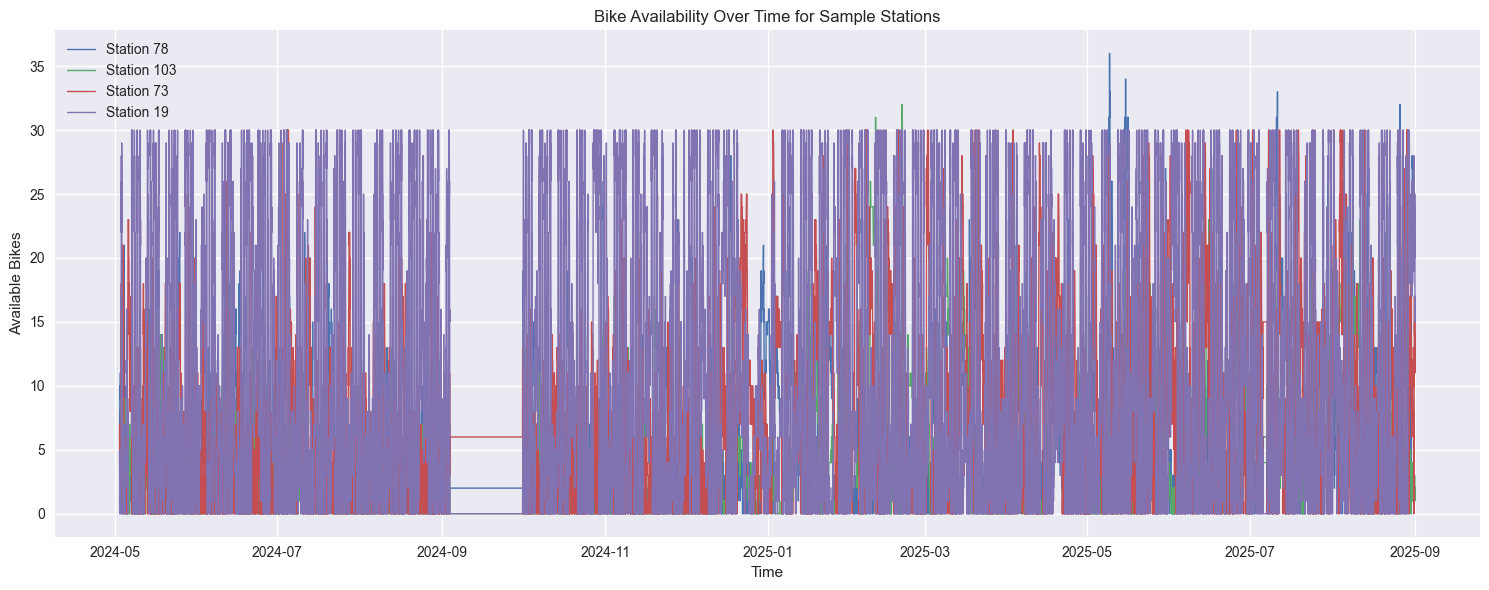

In [14]:
df_plot = df10[df10["station_id"].isin(sample_stations)]

plt.figure(figsize=(15, 6))
for sid in sample_stations:
    g = df_plot[df_plot["station_id"] == sid]
    plt.plot(g["last_reported"], g["num_bikes_available"], label=f"Station {sid}", linewidth=1)

plt.title("Bike Availability Over Time for Sample Stations")
plt.xlabel("Time")
plt.ylabel("Available Bikes")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
df10["hour"] = df10["last_reported"].dt.hour

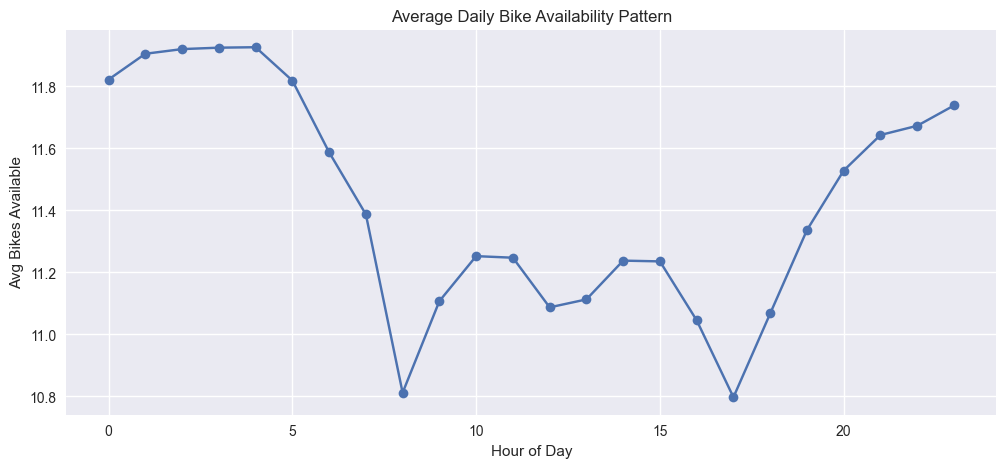

In [16]:
daily_mean = df10.groupby("hour")["num_bikes_available"].mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_mean.index, daily_mean.values, marker="o")
plt.title("Average Daily Bike Availability Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Avg Bikes Available")
plt.grid(True)
plt.show()

In [17]:
df10["weekday"] = df10["last_reported"].dt.day_name()

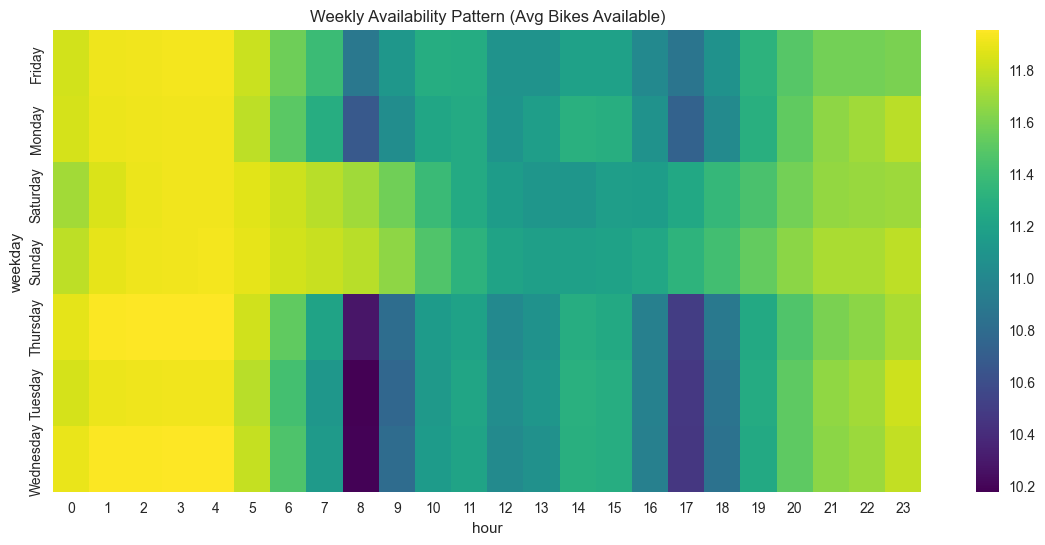

In [18]:
weekly = df10.groupby(["weekday", "hour"])["num_bikes_available"].mean().unstack()

plt.figure(figsize=(14, 6))
sns.heatmap(weekly, cmap="viridis")
plt.title("Weekly Availability Pattern (Avg Bikes Available)")
plt.show()

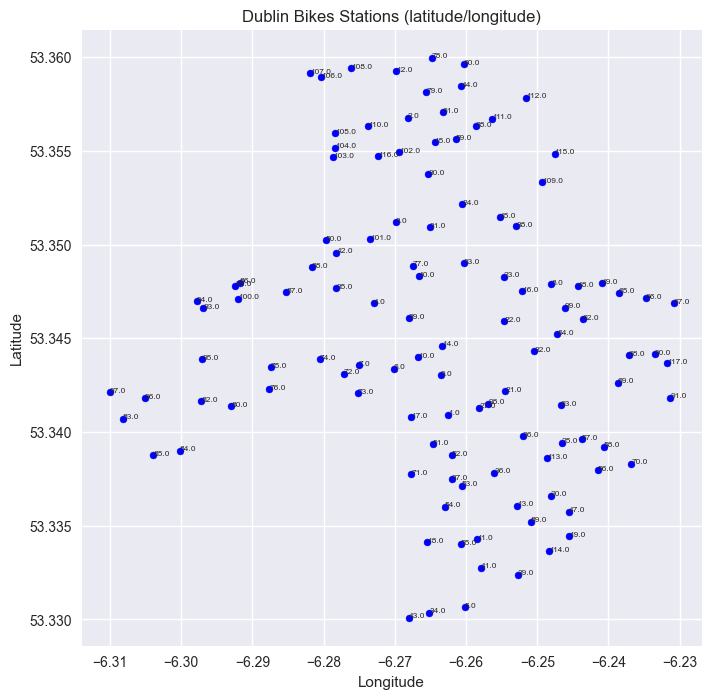

In [19]:
plt.figure(figsize=(8, 8))
plt.scatter(stations_from_data["lon"], stations_from_data["lat"], c="blue", s=25)
for _, row in stations_from_data.iterrows():
    plt.text(row["lon"], row["lat"], str(row["station_id"]), fontsize=6)

plt.title("Dublin Bikes Stations (latitude/longitude)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

In [20]:
df_wide = df10.pivot(index="last_reported", columns="station_id", values="num_bikes_available")
corr = df_wide.corr()

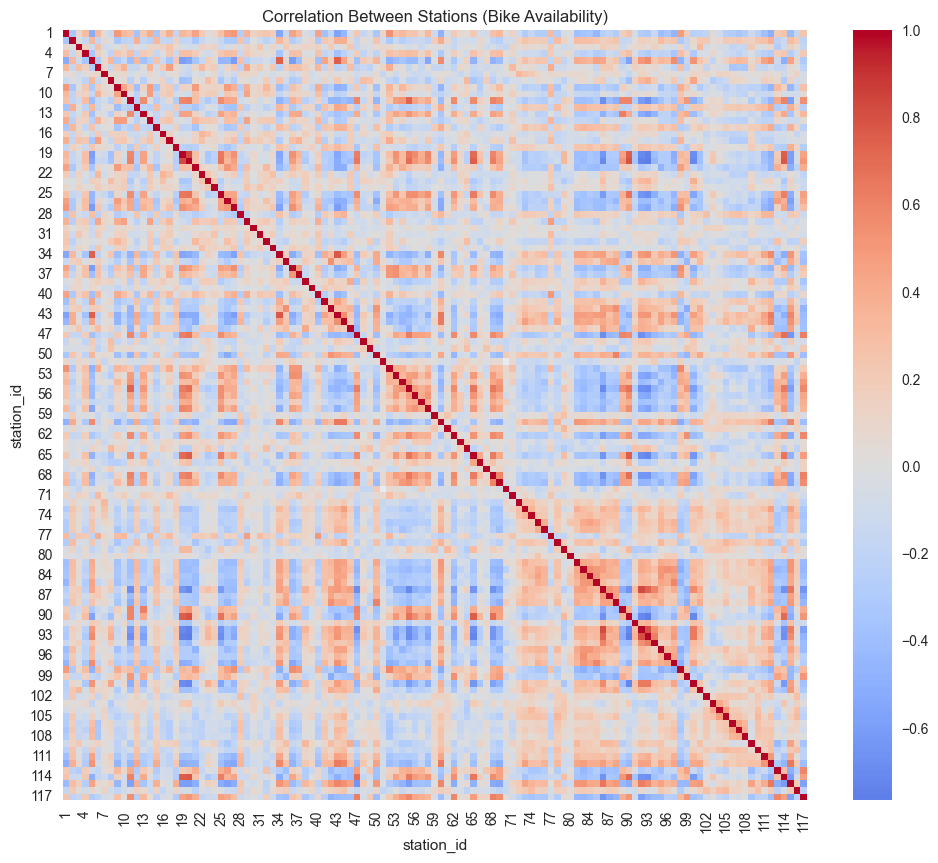

In [21]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Between Stations (Bike Availability)")
plt.show()

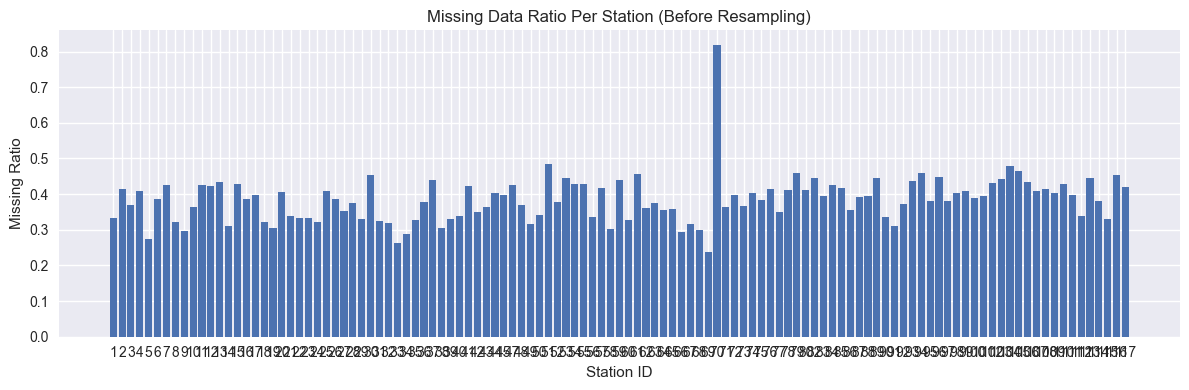

In [22]:
df_raw_missing = df_raw.pivot(index="last_reported", columns="station_id", values="num_bikes_available")
missing_ratio = df_raw_missing.isna().mean()

plt.figure(figsize=(12, 4))
plt.bar(missing_ratio.index.astype(str), missing_ratio.values)
plt.title("Missing Data Ratio Per Station (Before Resampling)")
plt.xlabel("Station ID")
plt.ylabel("Missing Ratio")
plt.tight_layout()
plt.show()

In [23]:
# Pivot to wide: rows = timestamps, columns = station_ids
df_wide = df10.pivot(
    index="last_reported",
    columns="station_id",
    values="num_bikes_available"
)

# Ensuring columns match station ordering
df_wide = df_wide[station_list]

# FIX: fill early missing values before normalization
df_wide = df_wide.ffill().bfill()

print("Any NaNs left?", df_wide.isna().any().any())

# Now converting to numpy
data = df_wide.values.astype(np.float32)
print("Data min/max:", data.min(), data.max(), "shape:", data.shape)

Any NaNs left? False
Data min/max: 0.0 40.0 shape: (70014, 115)


In [24]:
data = df_wide.values.astype(np.float32)   # shape: (T, N)
T, N = data.shape
print("Data min/max:", data.min(), data.max(), "shape:", data.shape)

# Z-score normalization per station
mean_per_station = data.mean(axis=0, keepdims=True)          # (1, N)
std_per_station  = data.std(axis=0, keepdims=True) + 1e-6    # (1, N)

data_norm = (data - mean_per_station) / std_per_station      # (T, N)
print("Normalized data shape:", data_norm.shape)

Data min/max: 0.0 40.0 shape: (70014, 115)
Normalized data shape: (70014, 115)


In [25]:
history_len = 18   # input length (3 hours)
horizon_len = 3    # output length (30 minutes)

#calendar encodings (hour-of-day + day-of-week)
time_index = pd.to_datetime(df_wide.index)  # ensure datetime index

tod = time_index.hour + (time_index.minute / 60.0)   # includes minutes (10-min data)
dow = time_index.dayofweek                           # 0..6

hour_sin = np.sin(2 * np.pi * tod / 24.0)
hour_cos = np.cos(2 * np.pi * tod / 24.0)
dow_sin  = np.sin(2 * np.pi * dow / 7.0)
dow_cos  = np.cos(2 * np.pi * dow / 7.0)

time_feat = np.stack([hour_sin, hour_cos, dow_sin, dow_cos], axis=-1).astype(np.float32)  # (T, 4)
assert time_feat.shape[0] == T

X_list = []
Y_list = []

for t in range(T - history_len - horizon_len + 1):
    # availability window (normalized)
    x_window = data_norm[t : t + history_len]  # (history_len, N)

    # time features for this window (broadcast across stations)
    tf_win = time_feat[t : t + history_len]                    # (history_len, 4)
    tf_win = np.repeat(tf_win[:, None, :], N, axis=1)          # (history_len, N, 4)

    # combine availability + time features -> (history_len, N, 5)
    x_window_feat = np.concatenate([x_window[..., None], tf_win], axis=-1)  # (history_len, N, 5)

    # target window stays in ORIGINAL scale
    y_window = data[t + history_len : t + history_len + horizon_len]  # (horizon_len, N)

    X_list.append(x_window_feat)
    Y_list.append(y_window)

X = np.stack(X_list, axis=0)   # (num_samples, history_len, N, 5)
Y = np.stack(Y_list, axis=0)   # (num_samples, horizon_len, N)

print("X raw shape (with time encodings):", X.shape)
print("Y raw shape:", Y.shape)

X raw shape (with time encodings): (69994, 18, 115, 5)
Y raw shape: (69994, 3, 115)


In [26]:
print("X shape (batch, T_in, N, F):", X.shape)
print("Y shape (targets):", Y.shape)

X shape (batch, T_in, N, F): (69994, 18, 115, 5)
Y shape (targets): (69994, 3, 115)


In [27]:
num_samples = X.shape[0]

train_ratio = 0.7
val_ratio   = 0.15   # test gets the remaining 0.15

train_end = int(num_samples * train_ratio)
val_end   = int(num_samples * (train_ratio + val_ratio))

X_train, Y_train = X[:train_end],      Y[:train_end]
X_val,   Y_val   = X[train_end:val_end], Y[train_end:val_end]
X_test,  Y_test  = X[val_end:],        Y[val_end:]

print("Train:", X_train.shape, Y_train.shape)
print("Val:  ", X_val.shape,   Y_val.shape)
print("Test: ", X_test.shape,  Y_test.shape)

Train: (48995, 18, 115, 5) (48995, 3, 115)
Val:   (10499, 18, 115, 5) (10499, 3, 115)
Test:  (10500, 18, 115, 5) (10500, 3, 115)


In [28]:
out_dir = r"C:\Users\suzak\Desktop\thesis\processed"
os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(out_dir, "dublinbikes_stgcn_data.npz")

np.savez_compressed(
    out_path,
    X_train=X_train, Y_train=Y_train,
    X_val=X_val,     Y_val=Y_val,
    X_test=X_test,   Y_test=Y_test,
    A=A,
    station_list=np.array(station_list),
    mean_per_station=mean_per_station,
    std_per_station=std_per_station,
)

print("Saved processed data to:", out_path)

Saved processed data to: C:\Users\suzak\Desktop\thesis\processed\dublinbikes_stgcn_data.npz


In [29]:
!pip install torch

In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [31]:
# Utility: Normalized adjacency matrix

def normalize_adjacency(A: torch.Tensor) -> torch.Tensor:
    N = A.size(0)
    A_hat = A + torch.eye(N, device=A.device)
    deg = A_hat.sum(dim=1)
    deg_inv_sqrt = torch.pow(deg, -0.5)
    deg_inv_sqrt[deg_inv_sqrt == float("inf")] = 0.0
    D_inv_sqrt = torch.diag(deg_inv_sqrt)
    return D_inv_sqrt @ A_hat @ D_inv_sqrt

In [32]:
# Graph convolution layer
class GraphConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.linear = nn.Linear(in_channels, out_channels)

    def forward(self, X, A_norm):
        B, T, N, F_in = X.shape
        X_flat = X.reshape(B * T, N, F_in)
        X_g = torch.matmul(A_norm, X_flat)
        out = self.linear(X_g)
        return out.reshape(B, T, N, -1)

In [33]:
# Temporal convolution layer
class TemporalConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.conv = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=(kernel_size, 1),
            padding=(padding, 0)
        )

    def forward(self, X):
        B, T, N, F = X.shape
        X_perm = X.permute(0, 3, 1, 2)
        out = self.conv(X_perm)
        out = out.permute(0, 2, 3, 1)
        return out

In [34]:
# ST-Conv block
class STConvBlock(nn.Module):
    def __init__(self, in_channels, spatial_channels, out_channels, kernel_size=3):
        super().__init__()
        self.temp1 = TemporalConv(in_channels, spatial_channels, kernel_size)
        self.graph_conv = GraphConv(spatial_channels, spatial_channels)
        self.temp2 = TemporalConv(spatial_channels, out_channels, kernel_size)

        if in_channels != out_channels:
            self.residual = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        else:
            self.residual = None

        self.relu = nn.ReLU()

    def forward(self, X, A_norm):
        out = self.relu(self.temp1(X))
        out = self.relu(self.graph_conv(out, A_norm))
        out = self.temp2(out)

        if self.residual is not None:
            res = X.permute(0, 3, 1, 2)
            res = self.residual(res)
            res = res.permute(0, 2, 3, 1)
        else:
            res = X

        return self.relu(out + res)

In [35]:
class STGCN(nn.Module):
    def __init__(self, num_nodes, in_channels=1,
                 spatial_channels=16, out_channels=32,
                 T_in=18, T_out=3, kernel_size=3):
        super().__init__()

        self.T_out = T_out  # remember horizon length

        self.block1 = STConvBlock(in_channels, spatial_channels, out_channels, kernel_size)
        self.block2 = STConvBlock(out_channels, spatial_channels, out_channels, kernel_size)

        # keep channel dim = out_channels, do NOT try to use T_out here
        self.temp_out = TemporalConv(out_channels, out_channels, kernel_size)

        # project from feature dim (out_channels) -> 1 value per node
        self.proj = nn.Linear(out_channels, 1)

    def forward(self, X, A_norm):
        # X: (B, T_in, N, F)
        out = self.block1(X, A_norm)   # (B, T_in, N, C)
        out = self.block2(out, A_norm) # (B, T_in, N, C)

        out = self.temp_out(out)       # (B, T_in, N, C)

        # take the last T_out time steps
        out = out[:, -self.T_out:, :, :]   # (B, T_out, N, C)

        B, T, N, C = out.shape             # T == T_out
        out = out.reshape(B * T * N, C)    # (B*T*N, C)
        out = self.proj(out)              # (B*T*N, 1)
        out = out.reshape(B, T, N)        # (B, T_out, N)

        return out

In [36]:
import torch
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
from torch.optim import Adam

# Dataset wrapper
class STDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

In [37]:
# Prepare data loaders
batch_size = 64

train_loader = DataLoader(STDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(STDataset(X_val,   Y_val),   batch_size=batch_size)
test_loader  = DataLoader(STDataset(X_test,  Y_test),  batch_size=batch_size)

In [38]:
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.


In [39]:
import torch
print(torch.cuda.is_available())

True


In [40]:
import torch
import torch.nn as nn
from torch.optim import Adam

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# Normalizing adjacency and move to device
A_norm = normalize_adjacency(
    torch.tensor(A, dtype=torch.float32)
).to(device)

# Initialize ST-GCN model
in_channels = X_train.shape[-1]

model = STGCN(
    num_nodes=A.shape[0],
    in_channels=in_channels,
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
).to(device)


# Optimizer + Loss
optimizer = Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.L1Loss()

Using: cuda


In [41]:
# Training loop
best_val = float("inf")

for epoch in range(1, 16):
    model.train()
    train_loss = 0

    for Xb, Yb in train_loader:
        Xb, Yb = Xb.to(device), Yb.to(device)
        optimizer.zero_grad()
        pred = model(Xb, A_norm)
        loss = criterion(pred, Yb)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * Xb.size(0)

    train_loss /= len(train_loader.dataset)

    # validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for Xb, Yb in val_loader:
            Xb, Yb = Xb.to(device), Yb.to(device)
            pred = model(Xb, A_norm)
            val_loss += criterion(pred, Yb).item() * Xb.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch:02d} | Train MAE {train_loss:.4f} | Val MAE {val_loss:.4f}")

    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "stgcn_best.pt")
        print(" → Saved best model!")


# Final test
model.load_state_dict(torch.load("stgcn_best.pt"))
model.eval()
test_loss = 0
with torch.no_grad():
    for Xb, Yb in test_loader:
        Xb, Yb = Xb.to(device), Yb.to(device)
        pred = model(Xb, A_norm)
        test_loss += criterion(pred, Yb).item() * Xb.size(0)
test_loss /= len(test_loader.dataset)

print(f"\nFINAL TEST MAE = {test_loss:.4f}")

Epoch 01 | Train MAE 4.6242 | Val MAE 4.1412
 → Saved best model!
Epoch 02 | Train MAE 3.9567 | Val MAE 4.0685
 → Saved best model!
Epoch 03 | Train MAE 3.9002 | Val MAE 4.0317
 → Saved best model!
Epoch 04 | Train MAE 3.8605 | Val MAE 4.0118
 → Saved best model!
Epoch 05 | Train MAE 3.8312 | Val MAE 3.9878
 → Saved best model!
Epoch 06 | Train MAE 3.8012 | Val MAE 3.9268
 → Saved best model!
Epoch 07 | Train MAE 3.7772 | Val MAE 3.8953
 → Saved best model!
Epoch 08 | Train MAE 3.7519 | Val MAE 3.9176
Epoch 09 | Train MAE 3.7325 | Val MAE 3.8629
 → Saved best model!
Epoch 10 | Train MAE 3.7144 | Val MAE 3.8888
Epoch 11 | Train MAE 3.6931 | Val MAE 3.8560
 → Saved best model!
Epoch 12 | Train MAE 3.6744 | Val MAE 3.8249
 → Saved best model!
Epoch 13 | Train MAE 3.6555 | Val MAE 3.8171
 → Saved best model!
Epoch 14 | Train MAE 3.6342 | Val MAE 3.7993
 → Saved best model!
Epoch 15 | Train MAE 3.6161 | Val MAE 3.7838
 → Saved best model!


C:\Users\suzak\AppData\Local\Temp\ipykernel_33180\3809137203.py:38: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("stgcn_best.pt"))



FINAL TEST MAE = 3.8842


In [42]:
!pip install tqdm

In [43]:
import numpy as np
import torch
from tqdm import tqdm

model.eval()
A_norm = A_norm

mae_per_station = np.zeros(115)
rmse_per_station = np.zeros(115)
count = np.zeros(115)

criterion = nn.L1Loss(reduction="none")

with torch.no_grad():
    for Xb, Yb in tqdm(test_loader):
        Xb = Xb.to(device)
        Yb = Yb.to(device)
        pred = model(Xb, A_norm)  # (B, 3, 115)

        # Compute absolute error per station
        err = torch.abs(pred - Yb).cpu().numpy()  # (B, 3, 115)

        mae_per_station += err.mean(axis=1).sum(axis=0)
        rmse_per_station += np.sqrt((err ** 2).mean(axis=1)).sum(axis=0)
        count += Xb.shape[0]

mae_per_station /= count
rmse_per_station /= count

print("MAE per station:", mae_per_station)
print("RMSE per station:", rmse_per_station)

100%|█████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 206.17it/s]

MAE per station: [ 3.80547512  3.00415257  3.12821994  2.98984162  7.9006965   5.83621968
  4.81144443  4.05139122  2.5234641   4.28914565  1.84005836  4.77627965
  2.58390141  5.33074162  4.07156734  2.8218011   5.99001688  2.20759496
  1.81453287  1.46423464  2.5763436   3.95526457  6.0670277   3.01555493
  1.88108063  1.96848157  2.4504502   2.69756256  4.50790132  4.35893048
  4.03836152  3.27908303  3.36798698  2.28226634  4.54620371  3.90832201
  1.55135984 10.54903783  4.71687396  3.39081748  4.01586989  4.24195755
  1.70040385  2.32154068  2.05643417  2.01646413  2.17165628  4.72780264
  3.74209201  6.94558695  4.04765442  1.32644773  1.60258044  3.10718449
  2.07799542  2.47571376  6.15771162  4.01042428  4.11510291  2.83976849
  2.60681553  4.18447842  5.58699899  2.45423903  2.84051789  3.90477978
  3.64575164  6.49576119 10.31463781  2.21448028  6.45835519  4.05114765
  3.54675657  3.4293762   4.51275026  2.93098275  3.50311672  3.65586297
  2.79057052  7.50390254  6.627176

Best station: 51 1.3264477325166975
Worst station: 89 11.226199564615886


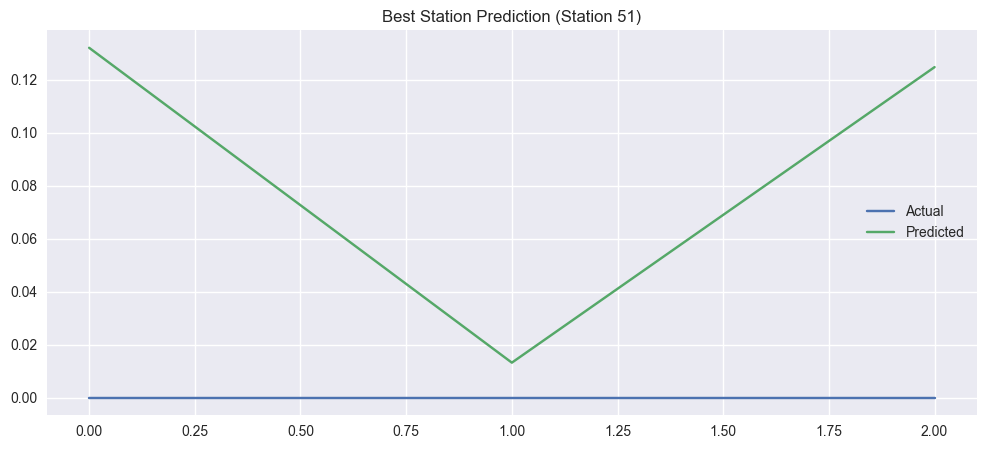

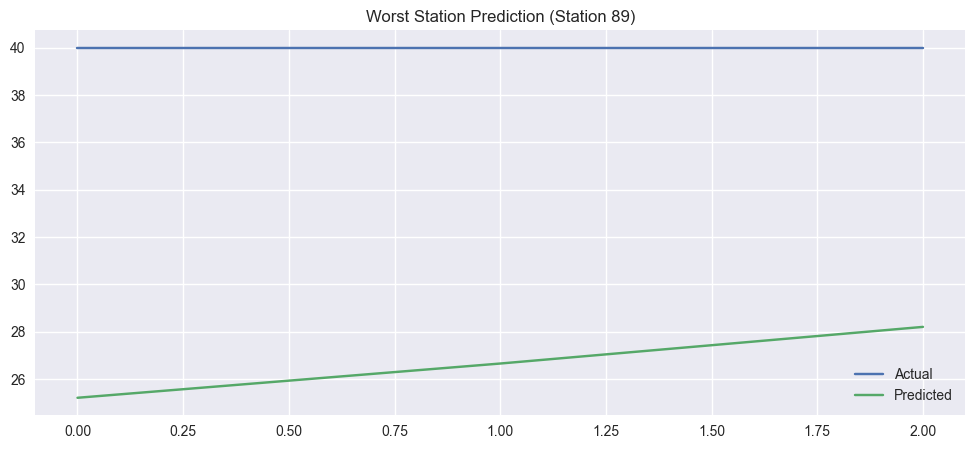

In [44]:
import matplotlib.pyplot as plt

best_st = np.argmin(mae_per_station)
worst_st = np.argmax(mae_per_station)

print("Best station:", best_st, mae_per_station[best_st])
print("Worst station:", worst_st, mae_per_station[worst_st])

# Taking one sample from the test set
Xb, Yb = next(iter(test_loader))
Xb = Xb.to(device)
pred = model(Xb, A_norm).cpu().detach().numpy()
Yb = Yb.numpy()

t = np.arange(3)

plt.figure(figsize=(12,5))
plt.plot(t, Yb[0,:,best_st], label="Actual")
plt.plot(t, pred[0,:,best_st], label="Predicted")
plt.title(f"Best Station Prediction (Station {best_st})")
plt.legend()
plt.show()

plt.figure(figsize=(12,5))
plt.plot(t, Yb[0,:,worst_st], label="Actual")
plt.plot(t, pred[0,:,worst_st], label="Predicted")
plt.title(f"Worst Station Prediction (Station {worst_st})")
plt.legend()
plt.show()

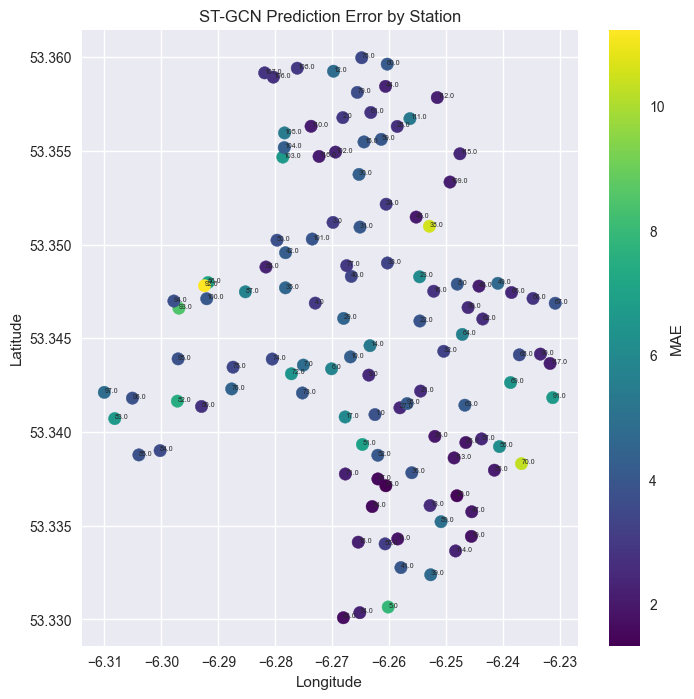

In [45]:
plt.figure(figsize=(8,8))
plt.scatter(stations_from_data["lon"], stations_from_data["lat"],
            c=mae_per_station, cmap="viridis", s=80)
plt.colorbar(label="MAE")
plt.title("ST-GCN Prediction Error by Station")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
for i, row in stations_from_data.iterrows():
    sid = row["station_id"]
    plt.text(row["lon"], row["lat"], str(sid), fontsize=5)
plt.show()

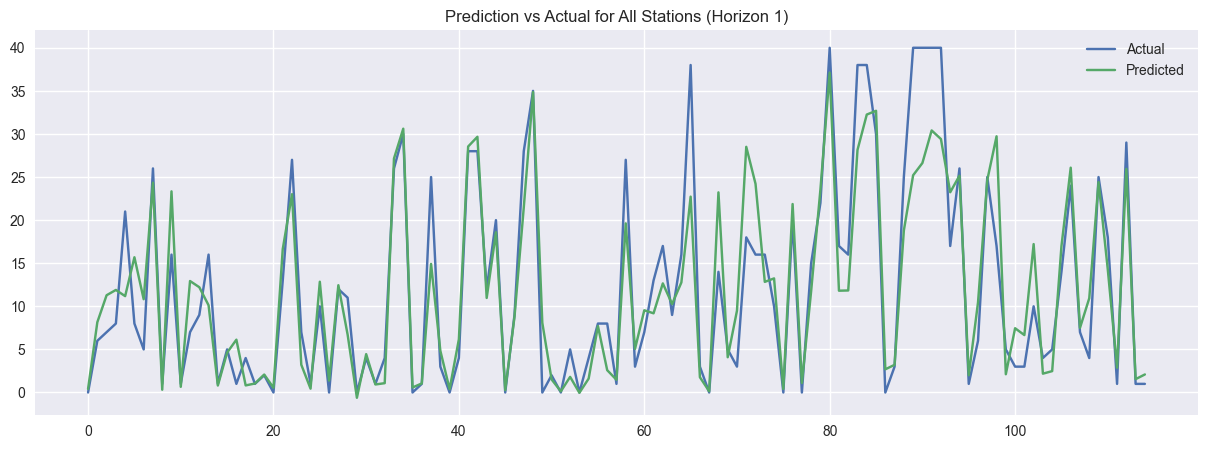

In [46]:
Xb, Yb = next(iter(test_loader))
Xb = Xb.to(device)
pred = model(Xb, A_norm).cpu().detach().numpy()
Yb = Yb.numpy()

# choose time horizon step 0 (first 10-minute future)
h = 0

plt.figure(figsize=(15,5))
plt.plot(Yb[0,h], label="Actual")
plt.plot(pred[0,h], label="Predicted")
plt.title("Prediction vs Actual for All Stations (Horizon 1)")
plt.legend()
plt.show()

In [47]:
# naive: predict last input value for future
def naive_mae():
    total = 0
    count = 0
    for Xb, Yb in test_loader:
        last_step = Xb[:, -1, :, 0]  # (B, N)
        naive_pred = np.repeat(last_step[:, None, :], 3, axis=1)
        err = np.abs(naive_pred - Yb.numpy()).mean()
        total += err * Xb.shape[0]
        count += Xb.shape[0]
    return total / count

print("Naive baseline MAE:", naive_mae())

Naive baseline MAE: tensor(11.5031)


In [48]:
import torch.nn as nn
from torch.nn import MultiheadAttention

class TemporalAttention(nn.Module):
    """
    Temporal self-attention over the time dimension, applied per node.
    Input:  X (B, T, N, C)
    Output: X_att (B, T, N, C)
    """
    def __init__(self, channels, num_heads=4, dropout=0.1):
        super().__init__()
        self.attn = MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,  # (B, T, C)
        )

    def forward(self, X):
        B, T, N, C = X.shape

        # reshape to (B*N, T, C) so each node has its own temporal attention
        x = X.permute(0, 2, 1, 3).reshape(B * N, T, C)  # (B*N, T, C)

        out, _ = self.attn(x, x, x)  # (B*N, T, C)

        # back to (B, T, N, C)
        out = out.reshape(B, N, T, C).permute(0, 2, 1, 3)
        return out


class ASTBlock(nn.Module):
    """
    ST-Conv block + Temporal Attention (residual).
    """
    def __init__(self, in_channels, spatial_channels, out_channels,
                 kernel_size=3, num_heads=4):
        super().__init__()
        self.st_block = STConvBlock(in_channels, spatial_channels,
                                    out_channels, kernel_size)
        self.tattn = TemporalAttention(out_channels,
                                       num_heads=num_heads, dropout=0.1)
        self.relu = nn.ReLU()

    def forward(self, X, A_norm):
        # ST-Conv part
        out = self.st_block(X, A_norm)     # (B, T, N, C)

        # Temporal attention
        attn_out = self.tattn(out)         # (B, T, N, C)

        # Residual fusion
        out = out + attn_out
        return self.relu(out)


class ASTGCN(nn.Module):
    """
    AST-GCN: ST-Conv blocks + Temporal Attention (TAM) on top.
    Input:  X (B, T_in, N, F_in)
    Output: Y_hat (B, T_out, N)
    """
    def __init__(self, num_nodes, in_channels=1,
                 spatial_channels=16, out_channels=32,
                 T_in=18, T_out=3, kernel_size=3,
                 num_heads=4):
        super().__init__()
        self.T_out = T_out

        self.block1 = ASTBlock(in_channels, spatial_channels, out_channels,
                               kernel_size, num_heads)
        self.block2 = ASTBlock(out_channels, spatial_channels, out_channels,
                               kernel_size, num_heads)

        # final temporal conv keeps time length, mixes channels
        self.temp_out = TemporalConv(out_channels, out_channels, kernel_size)

        # project per-node features to scalar
        self.proj = nn.Linear(out_channels, 1)

    def forward(self, X, A_norm):
        # X: (B, T_in, N, F)
        out = self.block1(X, A_norm)          # (B, T_in, N, C)
        out = self.block2(out, A_norm)        # (B, T_in, N, C)

        out = self.temp_out(out)              # (B, T_in, N, C)

        # take last T_out time steps
        out = out[:, -self.T_out:, :, :]      # (B, T_out, N, C)

        B, T, N, C = out.shape
        out = out.reshape(B * T * N, C)
        out = self.proj(out)                  # (B*T*N, 1)
        out = out.reshape(B, T, N)            # (B, T_out, N)

        return out

In [49]:
from tqdm.notebook import tqdm
from torch.optim import Adam

A_norm = normalize_adjacency(torch.tensor(A, dtype=torch.float32).to(device))

in_channels = X_train.shape[-1]

astgcn = ASTGCN(
    num_nodes=A.shape[0],
    in_channels=in_channels,
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
    kernel_size=3,
    num_heads=4,
).to(device)


optimizer = Adam(astgcn.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.L1Loss()

best_val = float("inf")
num_epochs = 20

for epoch in range(1, num_epochs + 1):
    
    # TRAINING
    astgcn.train()
    train_loss = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch:02d} [Training]", leave=False)

    for Xb, Yb in train_bar:
        Xb, Yb = Xb.to(device), Yb.to(device)
        optimizer.zero_grad()
        pred = astgcn(Xb, A_norm)
        loss = criterion(pred, Yb)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * Xb.size(0)
        train_bar.set_postfix(loss=loss.item())

    train_loss /= len(train_loader.dataset)

    # VALIDATION
    astgcn.eval()
    val_loss = 0.0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch:02d} [Validating]", leave=False)

    with torch.no_grad():
        for Xb, Yb in val_bar:
            Xb, Yb = Xb.to(device), Yb.to(device)
            pred = astgcn(Xb, A_norm)
            loss = criterion(pred, Yb)
            val_loss += loss.item() * Xb.size(0)
            val_bar.set_postfix(loss=loss.item())

    val_loss /= len(val_loader.dataset)

    print(f"\nEpoch {epoch:02d} | Train MAE {train_loss:.4f} | Val MAE {val_loss:.4f}")

    if val_loss < best_val:
        best_val = val_loss
        torch.save(astgcn.state_dict(), "astgcn_best.pt")
        print(" → Saved best AST-GCN model!")

# FINAL TEST EVALUATION
astgcn.load_state_dict(torch.load("astgcn_best.pt", map_location=device))
astgcn.eval()

test_loss = 0.0
with torch.no_grad():
    for Xb, Yb in tqdm(test_loader, desc="Testing"):
        Xb, Yb = Xb.to(device), Yb.to(device)
        pred = astgcn(Xb, A_norm)
        test_loss += criterion(pred, Yb).item() * Xb.size(0)

test_loss /= len(test_loader.dataset)
print(f"\nAST-GCN FINAL TEST MAE = {test_loss:.4f}")

Epoch 01 [Training]:   0%|          | 0/766 [00:00<?, ?it/s]

Epoch 01 [Validating]:   0%|          | 0/165 [00:00<?, ?it/s]


Epoch 01 | Train MAE 4.3631 | Val MAE 3.8429
 → Saved best AST-GCN model!


Epoch 02 [Training]:   0%|          | 0/766 [00:00<?, ?it/s]

Epoch 02 [Validating]:   0%|          | 0/165 [00:00<?, ?it/s]

...

Epoch 20 [Validating]:   0%|          | 0/165 [00:00<?, ?it/s]


Epoch 20 | Train MAE 2.8188 | Val MAE 2.9752
 → Saved best AST-GCN model!


C:\Users\suzak\AppData\Local\Temp\ipykernel_33180\3272671779.py:71: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  astgcn.load_state_dict(torch.load("astgcn_best.pt", map_loc

Testing:   0%|          | 0/165 [00:00<?, ?it/s]


AST-GCN FINAL TEST MAE = 3.0828


In [50]:
import numpy as np
import torch
import torch.nn as nn
from tqdm.notebook import tqdm

astgcn.eval()

mae_ast = np.zeros(115)
rmse_ast = np.zeros(115)
count = np.zeros(115)

criterion = nn.L1Loss(reduction="none")

with torch.no_grad():
    for Xb, Yb in tqdm(test_loader, desc="AST-GCN per-station metrics"):
        Xb, Yb = Xb.to(device), Yb.to(device)
        pred = astgcn(Xb, A_norm).cpu().numpy()
        Y = Yb.cpu().numpy()

        abs_err = np.abs(pred - Y)               # (B, 3, 115)
        sq_err = (pred - Y) ** 2                 # (B, 3, 115)

        # average over prediction horizons (3)
        mae_ast += abs_err.mean(axis=1).sum(axis=0)
        rmse_ast += np.sqrt(sq_err.mean(axis=1)).sum(axis=0)
        count += Xb.shape[0]

mae_ast /= count
rmse_ast /= count

print("AST-GCN MAE per station:", mae_ast)
print("AST-GCN RMSE per station:", rmse_ast)

AST-GCN per-station metrics:   0%|          | 0/165 [00:00<?, ?it/s]

AST-GCN MAE per station: [ 2.97582035  1.86088222  1.91177178  2.2456564   8.02352109  3.4397864
  3.3048723   3.86061429  2.24446399  4.92230975  1.53551199  2.81874117
  1.50152118  3.83296602  2.76490452  1.91154953  5.43641358  1.922738
  2.10030482  1.55024361  2.54929605  3.44941312  5.22481768  2.39266358
  1.32348341  1.55007504  2.48454097  2.90191155  3.74699997  2.54753238
  2.56098475  3.28037826  3.01053348  2.00969363  4.30967287  4.10324819
  1.21665558 11.03251074  2.9011004   1.44079661  2.47716333  4.14668164
  1.6846594   2.38102238  1.90058418  1.36635744  2.32335458  4.95734421
  2.92455956  2.52663599  3.65367399  1.16523966  1.81073062  1.43892691
  2.12856063  2.85635305  5.9274255   2.22380486  5.20696263  1.17573838
  2.39001838  4.11530837  5.82570776  1.93572101  2.50842933  2.51045101
  2.65504531  4.02401008 11.8735145   2.57063825  4.32226017  3.30823203
  2.43196118  3.53501469  3.18801287  2.93801332  2.0819612   2.05490841
  2.54867024  4.65857283  7.5

In [51]:
# Reloading the trained ST-GCN model
in_channels = X_train.shape[-1]

stgcn = STGCN(
    num_nodes=A.shape[0],
    in_channels=in_channels,
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
    kernel_size=3
).to(device)


stgcn.load_state_dict(torch.load("stgcn_best.pt", map_location=device))
stgcn.eval()

print("ST-GCN model loaded.")

ST-GCN model loaded.


C:\Users\suzak\AppData\Local\Temp\ipykernel_33180\2158978221.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  stgcn.load_state_dict(torch.load("stgcn_best.pt", map_locat

In [52]:
mae_stgcn = np.zeros(115)
count = np.zeros(115)

with torch.no_grad():
    for Xb, Yb in test_loader:
        Xb, Yb = Xb.to(device), Yb.to(device)
        pred = stgcn(Xb, A_norm).cpu().numpy()
        Y = Yb.cpu().numpy()

        err = np.abs(pred - Y)        # (B, 3, 115)
        mae_stgcn += err.mean(axis=1).sum(axis=0)
        count += Xb.shape[0]

mae_stgcn /= count

print("Done computing mae_stgcn.")

Done computing mae_stgcn.


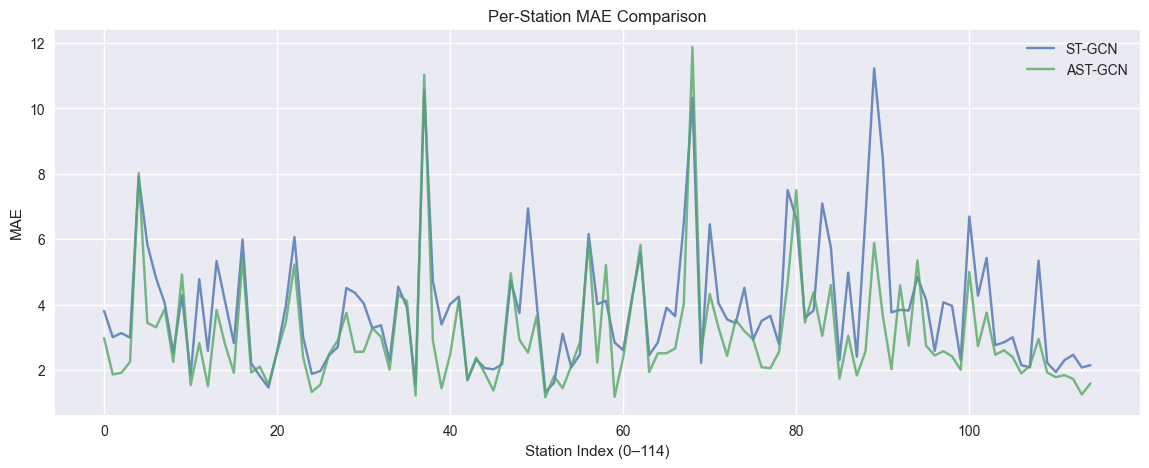

In [53]:
plt.figure(figsize=(14,5))
plt.plot(mae_stgcn, label="ST-GCN", alpha=0.8)
plt.plot(mae_ast, label="AST-GCN", alpha=0.8)
plt.title("Per-Station MAE Comparison")
plt.xlabel("Station Index (0–114)")
plt.ylabel("MAE")
plt.grid(True)
plt.legend()
plt.show()

In [54]:
best_ast = np.argmin(mae_ast)
worst_ast = np.argmax(mae_ast)

print("Best AST-GCN station:", best_ast, "MAE:", mae_ast[best_ast])
print("Worst AST-GCN station:", worst_ast, "MAE:", mae_ast[worst_ast])

Best AST-GCN station: 51 MAE: 1.1652396556309292
Worst AST-GCN station: 68 MAE: 11.873514498029436


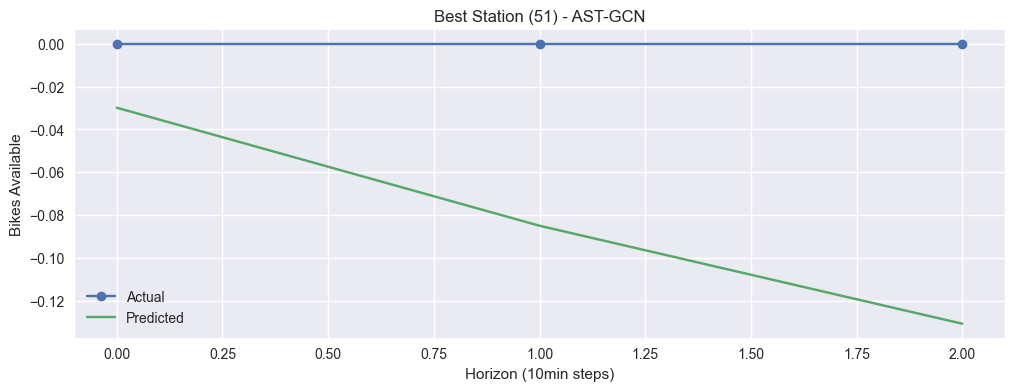

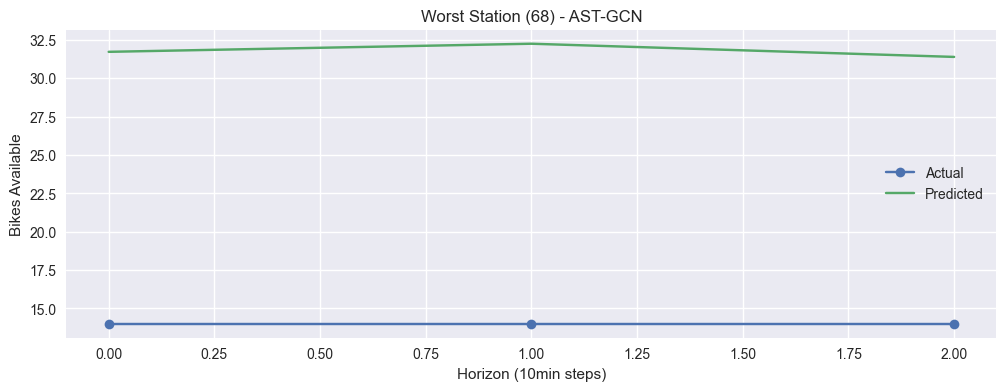

In [55]:
Xb, Yb = next(iter(test_loader))
Xb_gpu = Xb.to(device)

pred = astgcn(Xb_gpu, A_norm).cpu().detach().numpy()
Yb = Yb.numpy()

t = np.arange(3)

# Best station
plt.figure(figsize=(12,4))
plt.plot(t, Yb[0,:,best_ast], label="Actual", marker='o')
plt.plot(t, pred[0,:,best_ast], label="Predicted", marker='x')
plt.title(f"Best Station ({best_ast}) - AST-GCN")
plt.xlabel("Horizon (10min steps)")
plt.ylabel("Bikes Available")
plt.legend()
plt.grid(True)
plt.show()

# Worst station
plt.figure(figsize=(12,4))
plt.plot(t, Yb[0,:,worst_ast], label="Actual", marker='o')
plt.plot(t, pred[0,:,worst_ast], label="Predicted", marker='x')
plt.title(f"Worst Station ({worst_ast}) - AST-GCN")
plt.xlabel("Horizon (10min steps)")
plt.ylabel("Bikes Available")
plt.legend()
plt.grid(True)
plt.show()

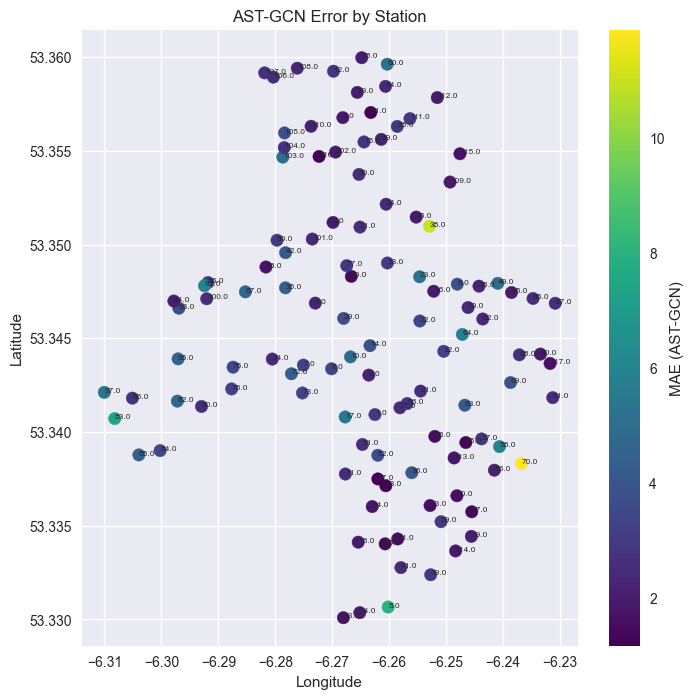

In [56]:
plt.figure(figsize=(8,8))
plt.scatter(stations_from_data["lon"], stations_from_data["lat"],
            c=mae_ast, cmap="viridis", s=80)
plt.colorbar(label="MAE (AST-GCN)")
plt.title("AST-GCN Error by Station")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

for _, row in stations_from_data.iterrows():
    sid = row["station_id"]
    plt.text(row["lon"], row["lat"], str(sid), fontsize=6)

plt.show()

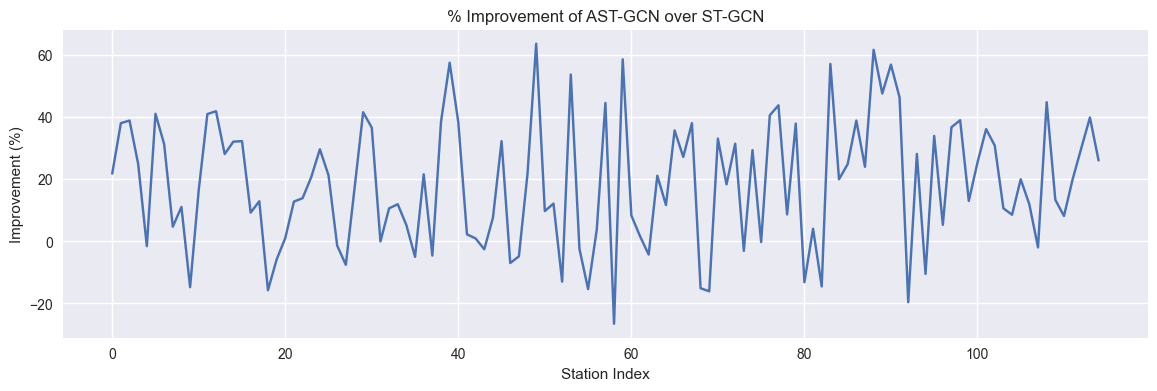

Average improvement: 18.588246795475683


In [57]:
improvement = (mae_stgcn - mae_ast) / mae_stgcn * 100

plt.figure(figsize=(14,4))
plt.plot(improvement)
plt.title("% Improvement of AST-GCN over ST-GCN")
plt.xlabel("Station Index")
plt.ylabel("Improvement (%)")
plt.grid(True)
plt.show()

print("Average improvement:", improvement.mean())

In [58]:
!pip install pyrosm geopandas shapely

In [59]:
import geopandas as gpd
from shapely.geometry import Point
from pyrosm import OSM
import numpy as np
import pandas as pd

In [60]:
from pyrosm import OSM
import geopandas as gpd
import matplotlib.pyplot as plt

osm_fp = r"C:\Users\suzak\Desktop\thesis\Dublin.osm.pbf"

osm = OSM(osm_fp)
pois = osm.get_pois()   # GeoDataFrame: points + polygons
pois.head()

,visible,tags,id,timestamp,version,changeset,lon,lat,addr:city,addr:country,...,museum,tourism,zoo,geometry,osm_type,fast_food,boat,fishing,swimming_pool,water
0,False,"{""brand"":""Applegreen"",""brand:wikidata"":""Q71789...",12244654,1727856050,7,157367624.0,-6.417798,53.383350,None,None,...,None,None,None,POINT (-6.4178 53.38335),node,NaN,NaN,NaN,NaN,NaN
1,False,"{""operator:type"":""council"",""operator:wikidata""...",27474191,1733350153,7,159935308.0,-6.391104,53.390900,None,None,...,None,None,None,POINT (-6.3911 53.3909),node,NaN,NaN,NaN,NaN,NaN
2,False,"{""created_by"":""YahooApplet 1.0"",""toilets:wheel...",27474239,1636628621,3,113643526.0,-6.391825,53.390961,None,None,...,None,None,None,POINT (-6.39183 53.39096),node,NaN,NaN,NaN,NaN,NaN
3,False,"{""brand"":""Circle K"",""brand:wikidata"":""Q3268010...",28851055,1697480017,8,142678350.0,-6.306985,53.399471,Dublin,None,...,None,None,None,POINT (-6.30699 53.39947),node,NaN,NaN,NaN,NaN,NaN
4,False,"{""access"":""yes"",""created_by"":""Potlatch 0.5d"",""...",29403586,1641741151,5,115946383.0,-6.291769,53.174702,None,None,...,None,None,None,POINT (-6.29177 53.1747),node,NaN,NaN,NaN,NaN,NaN


In [61]:
print("Total POIs:", len(pois))
print("\nColumns available:\n", pois.columns)

print("\nAmenity top 20:")
print(pois["amenity"].value_counts().head(20))

print("\nShop top 20:")
print(pois["shop"].value_counts().head(20))

print("\nTourism top 20:")
print(pois["tourism"].value_counts().head(20))

if "leisure" in pois.columns:
    print("\nLeisure top 20:")
    print(pois["leisure"].value_counts().head(20))
else:
    print("\nLeisure column not present in this OSM extract.")

Total POIs: 111936

Columns available:
 Index(['visible', 'tags', 'id', 'timestamp', 'version', 'changeset', 'lon',
       'lat', 'addr:city', 'addr:country', 'addr:full', 'addr:housenumber',
       'addr:housename', 'addr:postcode', 'addr:place', 'addr:street', 'email',
       'name', 'opening_hours', 'operator', 'phone', 'ref', 'url', 'website',
       'amenity', 'atm', 'bicycle_parking', 'bicycle_rental', 'bar',
       'biergarten', 'building', 'building:levels', 'cafe', 'car_wash',
       'childcare', 'college', 'doctors', 'drinking_water', 'fountain', 'fuel',
       'gambling', 'internet_access', 'kindergarten', 'landuse', 'office',
       'parking', 'post_office', 'pub', 'restaurant', 'school',
       'social_facility', 'source', 'start_date', 'wikipedia', 'alcohol',
       'bicycle', 'books', 'butcher', 'clothes', 'coffee', 'craft',
       'dry_cleaning', 'furniture', 'gift', 'hairdresser', 'kitchen',
       'massage', 'motorcycle', 'music', 'musical_instrument', 'organic',
    

In [62]:
pois_points = pois[pois.geometry.type == "Point"].copy()
print("Point POIs:", len(pois_points))
pois_points.head()

Point POIs: 25247


,visible,tags,id,timestamp,version,changeset,lon,lat,addr:city,addr:country,...,museum,tourism,zoo,geometry,osm_type,fast_food,boat,fishing,swimming_pool,water
0,False,"{""brand"":""Applegreen"",""brand:wikidata"":""Q71789...",12244654,1727856050,7,157367624.0,-6.417798,53.383350,None,None,...,None,None,None,POINT (-6.4178 53.38335),node,NaN,NaN,NaN,NaN,NaN
1,False,"{""operator:type"":""council"",""operator:wikidata""...",27474191,1733350153,7,159935308.0,-6.391104,53.390900,None,None,...,None,None,None,POINT (-6.3911 53.3909),node,NaN,NaN,NaN,NaN,NaN
2,False,"{""created_by"":""YahooApplet 1.0"",""toilets:wheel...",27474239,1636628621,3,113643526.0,-6.391825,53.390961,None,None,...,None,None,None,POINT (-6.39183 53.39096),node,NaN,NaN,NaN,NaN,NaN
3,False,"{""brand"":""Circle K"",""brand:wikidata"":""Q3268010...",28851055,1697480017,8,142678350.0,-6.306985,53.399471,Dublin,None,...,None,None,None,POINT (-6.30699 53.39947),node,NaN,NaN,NaN,NaN,NaN
4,False,"{""access"":""yes"",""created_by"":""Potlatch 0.5d"",""...",29403586,1641741151,5,115946383.0,-6.291769,53.174702,None,None,...,None,None,None,POINT (-6.29177 53.1747),node,NaN,NaN,NaN,NaN,NaN


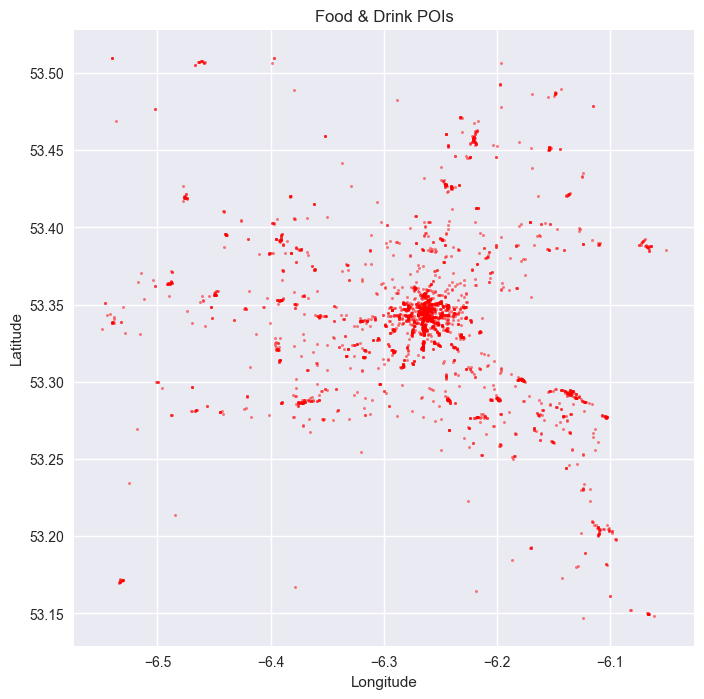

Food/drink POIs: 2967


In [63]:
food_mask = pois_points["amenity"].isin(["restaurant", "cafe", "pub", "bar", "fast_food"])
food_pois = pois_points[food_mask]

plt.figure(figsize=(8,8))
plt.scatter(food_pois.geometry.x, food_pois.geometry.y, s=3, alpha=0.5, color="red")
plt.title("Food & Drink POIs")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

print("Food/drink POIs:", len(food_pois))

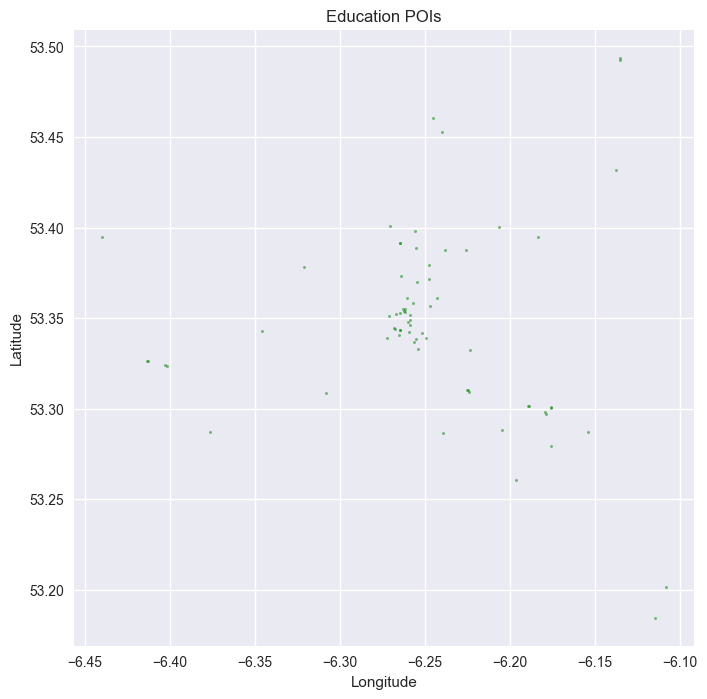

Education POIs: 71


In [64]:
edu_mask = pois_points["amenity"].isin(["school", "university", "college"])
edu_pois = pois_points[edu_mask]

plt.figure(figsize=(8,8))
plt.scatter(edu_pois.geometry.x, edu_pois.geometry.y, s=3, alpha=0.5, color="green")
plt.title("Education POIs")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

print("Education POIs:", len(edu_pois))

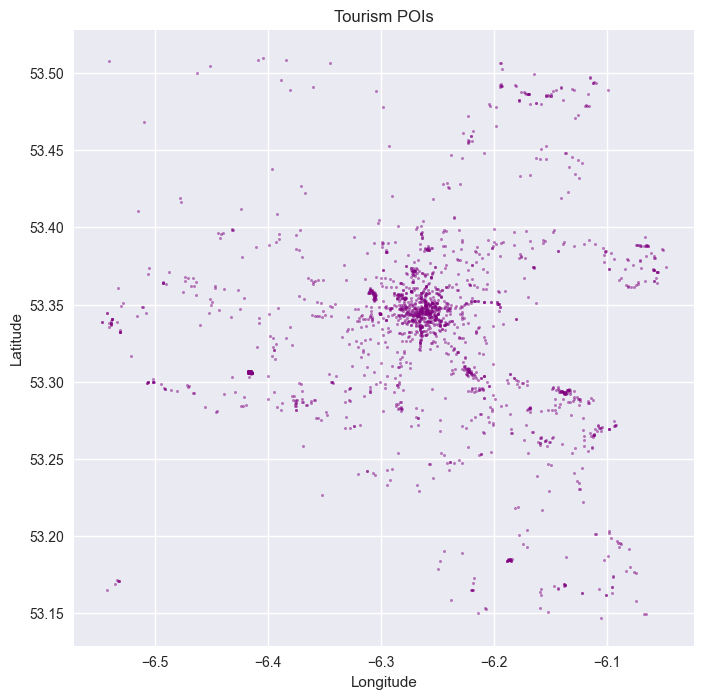

Tourism POIs: 1916


In [65]:
tour_pois = pois_points[pois_points["tourism"].notna()]

plt.figure(figsize=(8,8))
plt.scatter(tour_pois.geometry.x, tour_pois.geometry.y, s=3, alpha=0.5, color="purple")
plt.title("Tourism POIs")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

print("Tourism POIs:", len(tour_pois))

In [66]:
categories = {
    "food_drink": ["restaurant", "cafe", "pub", "bar", "fast_food"],
    "education": ["school", "university", "college"],
    "healthcare": ["hospital", "clinic", "doctors"],
    "transport": ["bus_station", "taxi", "ferry_terminal"],
}

summary = {}

for name, keys in categories.items():
    mask = pois_points["amenity"].isin(keys)
    summary[name] = mask.sum()

summary

{'food_drink': 2967, 'education': 71, 'healthcare': 278, 'transport': 96}

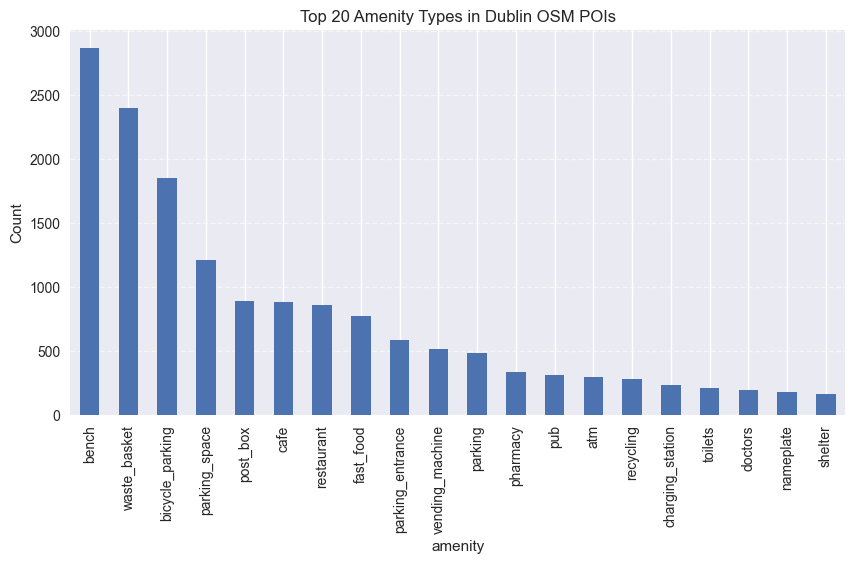

In [67]:
amenity_counts = pois_points["amenity"].value_counts().head(20)

plt.figure(figsize=(10,5))
amenity_counts.plot(kind="bar")
plt.title("Top 20 Amenity Types in Dublin OSM POIs")
plt.ylabel("Count")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

In [68]:
!pip install h3==3.7.7 folium geopandas shapely pyrosm

In [69]:
import h3
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon
import folium
import matplotlib.pyplot as plt

In [70]:
cols = ["name", "amenity", "shop", "tourism", "geometry"]
existing_cols = [c for c in cols if c in pois.columns]

pois = pois[existing_cols].dropna(subset=["geometry"]).copy()

print("POIs with geometry:", len(poiss := pois))
pois.head()

POIs with geometry: 111936


,name,amenity,shop,tourism,geometry
0,Applegreen,fuel,None,None,POINT (-6.4178 53.38335)
1,Blanchardstown Library,library,None,None,POINT (-6.3911 53.3909)
2,Draíocht,theatre,None,None,POINT (-6.39183 53.39096)
3,Circle K,fuel,None,None,POINT (-6.30699 53.39947)
4,None,parking,None,None,POINT (-6.29177 53.1747)


In [71]:
h3_res = 9  # city-scale resolution

def geom_to_h3(geom):
    c = geom.centroid  # works for Point or Polygon
    return h3.geo_to_h3(c.y, c.x, h3_res)

pois["h3_index"] = pois["geometry"].apply(geom_to_h3)
pois[["h3_index"]].head()

,h3_index
0,89182c1007bffff
1,89182c1054bffff
2,89182c1054bffff
3,89182c12c1bffff
4,89182c0621bffff


In [72]:
h3_counts = (
    pois.groupby("h3_index")
    .size()
    .reset_index(name="poi_count")
)

h3_counts.head()

,h3_index,poi_count
0,89182c0000bffff,1
1,89182c00093ffff,1
2,89182c00113ffff,2
3,89182c00133ffff,1
4,89182c0018bffff,3


In [73]:
h3_counts["geometry"] = h3_counts["h3_index"].apply(
    lambda h: Polygon(h3.h3_to_geo_boundary(h, geo_json=True))
)

gdf_hex = gpd.GeoDataFrame(
    h3_counts,
    geometry="geometry",
    crs="EPSG:4326"
)

gdf_hex.head()

,h3_index,poi_count,geometry
0,89182c0000bffff,1,"POLYGON ((-6.4859 53.25003, -6.48804 53.24894,..."
1,89182c00093ffff,1,"POLYGON ((-6.47159 53.25937, -6.47373 53.25828..."
2,89182c00113ffff,2,"POLYGON ((-6.45509 53.23665, -6.45723 53.23556..."
3,89182c00133ffff,1,"POLYGON ((-6.4496 53.22907, -6.45174 53.22799,..."
4,89182c0018bffff,3,"POLYGON ((-6.45362 53.23947, -6.45576 53.23838..."


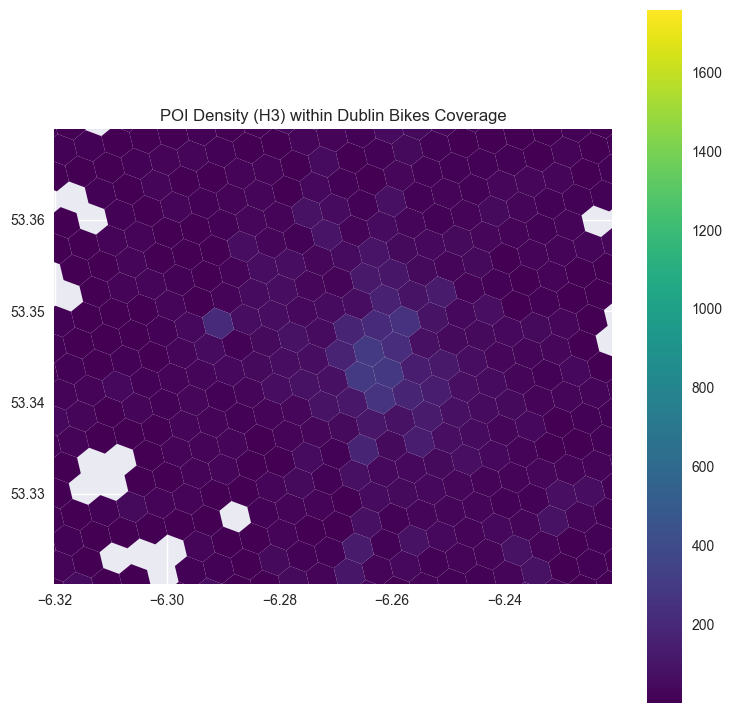

In [74]:
lon_min, lon_max = stations_from_data["lon"].min(), stations_from_data["lon"].max()
lat_min, lat_max = stations_from_data["lat"].min(), stations_from_data["lat"].max()

pad = 0.01

fig, ax = plt.subplots(figsize=(9, 9))
gdf_hex.plot(
    column="poi_count",
    ax=ax,
    legend=True,
    cmap="viridis"
)

ax.set_xlim(lon_min - pad, lon_max + pad)
ax.set_ylim(lat_min - pad, lat_max + pad)

ax.set_title("POI Density (H3) within Dublin Bikes Coverage")
plt.show()

In [75]:
m = folium.Map(
    location=[53.35, -6.26],
    zoom_start=12,
    tiles="cartodbpositron"
)

max_count = gdf_hex["poi_count"].max()

folium.GeoJson(
    gdf_hex,
    style_function=lambda feat: {
        "fillColor": "#3186cc",
        "color": "black",
        "weight": 0.2,
        "fillOpacity": (
            feat["properties"]["poi_count"] / max_count
            if max_count > 0 else 0
        ),
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["poi_count"],
        aliases=["POI count:"]
    )
).add_to(m)

m

In [76]:
for _, r in stations_from_data.iterrows():
    folium.CircleMarker(
        location=[r["lat"], r["lon"]],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.9,
        tooltip=f"Station {int(r['station_id'])}"
    ).add_to(m)

m

In [77]:
h3_counts.to_csv("dublin_h3_poi_counts.csv", index=False)
gdf_hex.to_file("dublin_h3_poi_counts.geojson", driver="GeoJSON")
m.save("dublin_poi_h3_map.html")

In [78]:
h3_res = 9

# stations_from_data has: station_id, lat, lon
stations_df = stations_from_data.copy()
stations_df["h3_index"] = stations_df.apply(
    lambda r: h3.geo_to_h3(r["lat"], r["lon"], h3_res),
    axis=1
)
stations_df[["station_id", "h3_index"]].head()

,station_id,h3_index
0,1,89182c17407ffff
1,2,89182c8da6bffff
2,3,89182c174c3ffff
3,4,89182c174cfffff
4,5,89182c1755bffff


In [79]:
def classify_poi(row):
    amenity = row.get("amenity")
    shop = row.get("shop")
    tourism = row.get("tourism")

    if amenity in ["restaurant", "cafe", "pub", "bar", "fast_food"]:
        return "food_drink"
    if amenity in ["school", "university", "college", "kindergarten", "library"]:
        return "education"
    if amenity in ["hospital", "clinic", "doctors", "pharmacy", "dentist"]:
        return "healthcare"
    if tourism in ["attraction", "museum", "gallery", "hotel", "hostel"]:
        return "tourism"
    if pd.notna(shop):
        return "shopping"
    return "other"

#this uses already-cleaned 'pois' that has h3_index
pois_feat = pois.copy()
pois_feat["poi_type"] = pois_feat.apply(classify_poi, axis=1)

h3_poi_types = (
    pois_feat
    .groupby(["h3_index", "poi_type"])
    .size()
    .unstack(fill_value=0)
)

poi_cols = list(h3_poi_types.columns)
print("POI feature columns:", poi_cols)
h3_poi_types.head()

POI feature columns: ['education', 'food_drink', 'healthcare', 'other', 'shopping', 'tourism']


poi_type,education,food_drink,healthcare,other,shopping,tourism
h3_index,,,,,,
89182c0000bffff,0,0,0,1,0,0
89182c00093ffff,0,0,0,1,0,0
89182c00113ffff,1,0,0,1,0,0
89182c00133ffff,0,0,0,1,0,0
89182c0018bffff,0,1,0,2,0,0


In [80]:
station_h3 = (
    stations_df[["station_id", "h3_index"]]
    .merge(h3_poi_types, how="left", on="h3_index")
    .fillna(0)
)

# align to your exact station order used in X tensors
station_h3 = station_h3.set_index("station_id").loc[station_list].reset_index()

station_h3_features = station_h3[["station_id"] + poi_cols].copy()
station_h3_features.head()

,station_id,education,food_drink,healthcare,other,shopping,tourism
0,1,3,54,4,65,132,7
1,2,1,8,6,23,14,2
2,3,1,11,0,31,8,0
3,4,0,4,0,39,5,2
4,5,1,3,0,36,3,1


In [81]:
poi_vec = station_h3_features.drop(columns=["station_id"]).values.astype(np.float32)

poi_mean = poi_vec.mean(axis=0, keepdims=True)
poi_std  = poi_vec.std(axis=0, keepdims=True) + 1e-6
poi_norm = (poi_vec - poi_mean) / poi_std

print("poi_norm shape:", poi_norm.shape)  # (115, F_poi)

poi_norm shape: (115, 6)


In [82]:
def add_static_node_features(X, node_feat):
    # X: (B, T, N, F), node_feat: (N, F2)
    B, T, N, F = X.shape
    F2 = node_feat.shape[1]
    static = np.broadcast_to(node_feat[None, None, :, :], (B, T, N, F2))
    return np.concatenate([X, static], axis=-1)

X_train_poi = add_static_node_features(X_train, poi_norm)
X_val_poi   = add_static_node_features(X_val,   poi_norm)
X_test_poi  = add_static_node_features(X_test,  poi_norm)

print("Old X:", X_train.shape, "New X:", X_train_poi.shape)

Old X: (48995, 18, 115, 5) New X: (48995, 18, 115, 11)


In [83]:
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

A_norm = normalize_adjacency(torch.tensor(A, dtype=torch.float32)).to(device)

Using: cuda


In [84]:
batch_size = 64

train_loader_poi = DataLoader(STDataset(X_train_poi, Y_train), batch_size=batch_size, shuffle=True)
val_loader_poi   = DataLoader(STDataset(X_val_poi,   Y_val),   batch_size=batch_size, shuffle=False)
test_loader_poi  = DataLoader(STDataset(X_test_poi,  Y_test),  batch_size=batch_size, shuffle=False)

In [85]:
def train_loop(model, train_loader, val_loader, A_norm, epochs=15, lr=1e-3, wd=1e-5, save_path="best.pt"):
    model = model.to(device)
    opt = Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit = nn.L1Loss()
    best_val = float("inf")

    for epoch in range(1, epochs + 1):
        model.train()
        tr_sum = 0.0
        for Xb, Yb in train_loader:
            Xb = Xb.to(device)
            Yb = Yb.to(device)

            opt.zero_grad()
            pred = model(Xb, A_norm)
            loss = crit(pred, Yb)
            loss.backward()
            opt.step()
            tr_sum += loss.item() * Xb.size(0)

        tr_mae = tr_sum / len(train_loader.dataset)

        model.eval()
        va_sum = 0.0
        with torch.no_grad():
            for Xb, Yb in val_loader:
                Xb = Xb.to(device)
                Yb = Yb.to(device)
                pred = model(Xb, A_norm)
                va_sum += crit(pred, Yb).item() * Xb.size(0)

        va_mae = va_sum / len(val_loader.dataset)

        print(f"Epoch {epoch:02d} | Train MAE {tr_mae:.4f} | Val MAE {va_mae:.4f}")

        if va_mae < best_val:
            best_val = va_mae
            torch.save(model.state_dict(), save_path)
            print(f"  → saved {save_path}")

    model.load_state_dict(torch.load(save_path, map_location=device))
    return model

In [86]:
in_channels_poi = X_train_poi.shape[-1]

stgcn_poi = STGCN(
    num_nodes=A.shape[0],
    in_channels=in_channels_poi,
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
).to(device)

stgcn_poi = train_loop(
    stgcn_poi,
    train_loader_poi,
    val_loader_poi,
    A_norm,
    epochs=15,
    save_path="stgcn_poi_best.pt"
)

Epoch 01 | Train MAE 3.2170 | Val MAE 2.0141
  → saved stgcn_poi_best.pt
Epoch 02 | Train MAE 1.6802 | Val MAE 1.6902
  → saved stgcn_poi_best.pt
Epoch 03 | Train MAE 1.4412 | Val MAE 1.5092
  → saved stgcn_poi_best.pt
Epoch 04 | Train MAE 1.3133 | Val MAE 1.4412
  → saved stgcn_poi_best.pt
Epoch 05 | Train MAE 1.2528 | Val MAE 1.4039
  → saved stgcn_poi_best.pt
Epoch 06 | Train MAE 1.2065 | Val MAE 1.3781
  → saved stgcn_poi_best.pt
Epoch 07 | Train MAE 1.1837 | Val MAE 1.3607
  → saved stgcn_poi_best.pt
Epoch 08 | Train MAE 1.1561 | Val MAE 1.3165
  → saved stgcn_poi_best.pt
Epoch 09 | Train MAE 1.1442 | Val MAE 1.2579
  → saved stgcn_poi_best.pt
Epoch 10 | Train MAE 1.1233 | Val MAE 1.2695
Epoch 11 | Train MAE 1.1170 | Val MAE 1.2330
  → saved stgcn_poi_best.pt
Epoch 12 | Train MAE 1.0967 | Val MAE 1.2297
  → saved stgcn_poi_best.pt
Epoch 13 | Train MAE 1.0969 | Val MAE 1.2070
  → saved stgcn_poi_best.pt
Epoch 14 | Train MAE 1.0833 | Val MAE 1.1999
  → saved stgcn_poi_best.pt
Epoch 

C:\Users\suzak\AppData\Local\Temp\ipykernel_33180\550852135.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(save_path, map_location=dev

In [87]:
astgcn_poi = ASTGCN(
    num_nodes=A.shape[0],
    in_channels=in_channels_poi,
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
    kernel_size=3,
    num_heads=4,
).to(device)

astgcn_poi = train_loop(
    astgcn_poi,
    train_loader_poi,
    val_loader_poi,
    A_norm,
    epochs=15,
    save_path="astgcn_poi_best.pt"
)

Epoch 01 | Train MAE 2.6851 | Val MAE 1.7681
  → saved astgcn_poi_best.pt
Epoch 02 | Train MAE 1.3909 | Val MAE 1.2686
  → saved astgcn_poi_best.pt
Epoch 03 | Train MAE 1.1256 | Val MAE 1.1377
  → saved astgcn_poi_best.pt
Epoch 04 | Train MAE 1.0389 | Val MAE 1.0915
  → saved astgcn_poi_best.pt
Epoch 05 | Train MAE 0.9928 | Val MAE 1.0628
  → saved astgcn_poi_best.pt
Epoch 06 | Train MAE 0.9631 | Val MAE 1.0764
Epoch 07 | Train MAE 0.9354 | Val MAE 1.1307
Epoch 08 | Train MAE 0.9239 | Val MAE 1.0887
Epoch 09 | Train MAE 0.9067 | Val MAE 1.1916
Epoch 10 | Train MAE 0.8954 | Val MAE 1.0433
  → saved astgcn_poi_best.pt
Epoch 11 | Train MAE 0.8898 | Val MAE 1.0266
  → saved astgcn_poi_best.pt
Epoch 12 | Train MAE 0.8787 | Val MAE 1.0961
Epoch 13 | Train MAE 0.8700 | Val MAE 1.2131
Epoch 14 | Train MAE 0.8694 | Val MAE 1.0346
Epoch 15 | Train MAE 0.8647 | Val MAE 1.0748


C:\Users\suzak\AppData\Local\Temp\ipykernel_33180\550852135.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(save_path, map_location=dev

In [88]:
def eval_mae(model, loader, A_norm):
    crit = nn.L1Loss()
    model.eval()
    total = 0.0
    with torch.no_grad():
        for Xb, Yb in loader:
            Xb = Xb.to(device)
            Yb = Yb.to(device)
            pred = model(Xb, A_norm)
            total += crit(pred, Yb).item() * Xb.size(0)
    return total / len(loader.dataset)

poi_stgcn_mae = eval_mae(stgcn_poi, test_loader_poi, A_norm)
poi_astgcn_mae = eval_mae(astgcn_poi, test_loader_poi, A_norm)

print("POI-STGCN Test MAE:", poi_stgcn_mae)
print("POI-ASTGCN Test MAE:", poi_astgcn_mae)

POI-STGCN Test MAE: 1.2424665478297643
POI-ASTGCN Test MAE: 1.063909074351901


In [89]:
stgcn_poi.load_state_dict(
    torch.load("stgcn_poi_best.pt", map_location=device, weights_only=True)
)
stgcn_poi.eval()

STGCN(
  (block1): STConvBlock(
    (temp1): TemporalConv(
      (conv): Conv2d(11, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (graph_conv): GraphConv(
      (linear): Linear(in_features=16, out_features=16, bias=True)
    )
    (temp2): TemporalConv(
      (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (residual): Conv2d(11, 32, kernel_size=(1, 1), stride=(1, 1))
    (relu): ReLU()
  )
  (block2): STConvBlock(
    (temp1): TemporalConv(
      (conv): Conv2d(32, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (graph_conv): GraphConv(
      (linear): Linear(in_features=16, out_features=16, bias=True)
    )
    (temp2): TemporalConv(
      (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (relu): ReLU()
  )
  (temp_out): TemporalConv(
    (conv): Conv2d(32, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
  )
  (proj): Linear(in_features=32, out_features=1, bias=True)
)

In [90]:
criterion = nn.L1Loss()
test_loss = 0.0

with torch.no_grad():
    for Xb, Yb in test_loader_poi:
        Xb = Xb.to(device)
        Yb = Yb.to(device)
        pred = stgcn_poi(Xb, A_norm)
        test_loss += criterion(pred, Yb).item() * Xb.size(0)

test_loss /= len(test_loader_poi.dataset)
print(f"POI-STGCN FINAL TEST MAE = {test_loss:.4f}")

POI-STGCN FINAL TEST MAE = 1.2425


In [91]:
mae_poi = np.zeros(115)
rmse_poi = np.zeros(115)
count = np.zeros(115)

with torch.no_grad():
    for Xb, Yb in test_loader_poi:
        Xb = Xb.to(device)
        Yb = Yb.to(device)
        pred = stgcn_poi(Xb, A_norm).cpu().numpy()
        Y = Yb.cpu().numpy()

        err = np.abs(pred - Y)
        sq = (pred - Y) ** 2

        mae_poi += err.mean(axis=1).sum(axis=0)
        rmse_poi += np.sqrt(sq.mean(axis=1)).sum(axis=0)
        count += Xb.shape[0]

mae_poi /= count
rmse_poi /= count

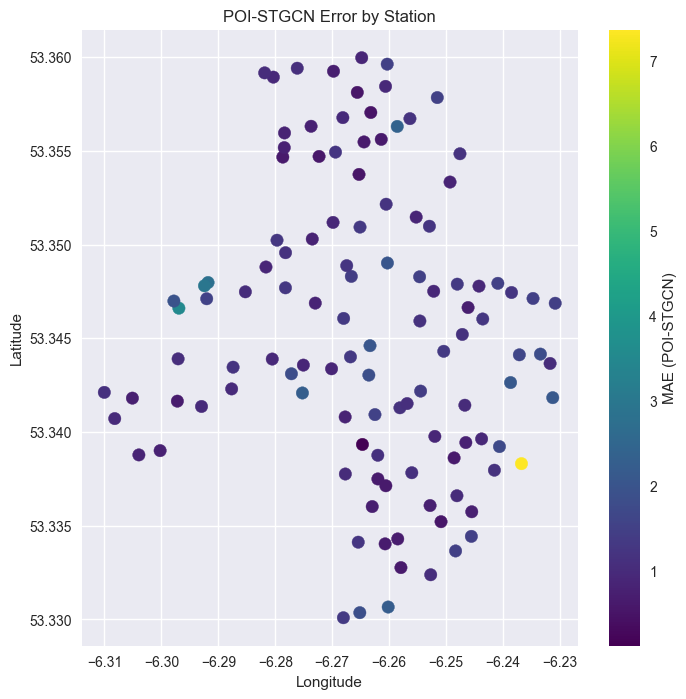

In [92]:
plt.figure(figsize=(8,8))
plt.scatter(
    stations_from_data["lon"],
    stations_from_data["lat"],
    c=mae_poi,
    cmap="viridis",
    s=80
)
plt.colorbar(label="MAE (POI-STGCN)")
plt.title("POI-STGCN Error by Station")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

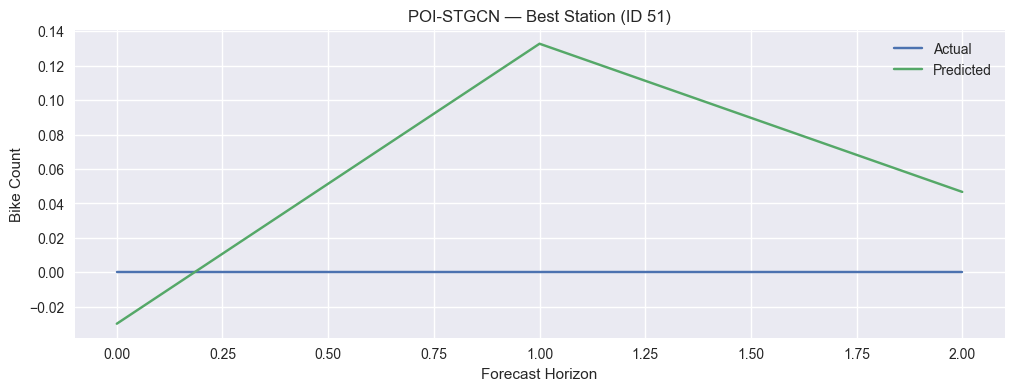

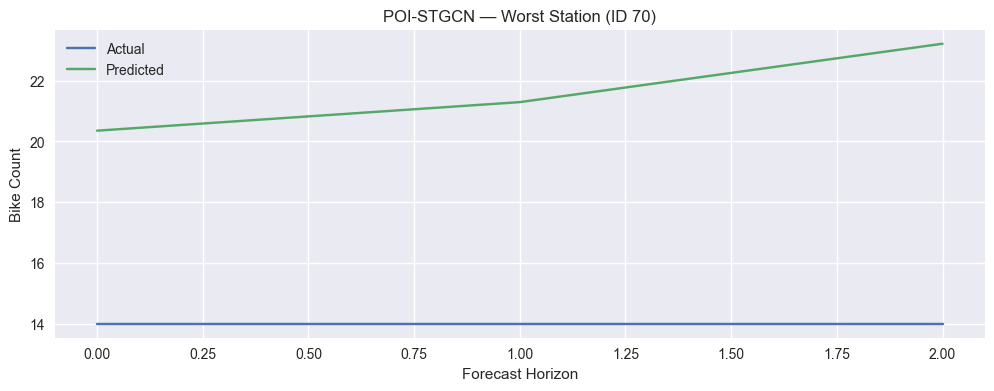

In [93]:
# picking best and worst stations based on MAE
best_station = np.argmin(mae_poi)
worst_station = np.argmax(mae_poi)

# getting one batch from test loader
Xb, Yb = next(iter(test_loader_poi))
Xb = Xb.to(device)

# forward pass WITHOUT gradient tracking
with torch.no_grad():
    pred = stgcn_poi(Xb, A_norm).cpu().numpy()

Yb = Yb.numpy()

# time axis (3-step forecast)
t = np.arange(pred.shape[1])

# Best station plot
plt.figure(figsize=(12,4))
plt.plot(t, Yb[0, :, best_station], label="Actual")
plt.plot(t, pred[0, :, best_station], label="Predicted")
plt.title(f"POI-STGCN — Best Station (ID {station_list[best_station]})")
plt.xlabel("Forecast Horizon")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

# Worst station plot
plt.figure(figsize=(12,4))
plt.plot(t, Yb[0, :, worst_station], label="Actual")
plt.plot(t, pred[0, :, worst_station], label="Predicted")
plt.title(f"POI-STGCN — Worst Station (ID {station_list[worst_station]})")
plt.xlabel("Forecast Horizon")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

In [94]:
astgcn_poi.load_state_dict(
    torch.load("astgcn_poi_best.pt", map_location=device, weights_only=True)
)
astgcn_poi.eval()

ASTGCN(
  (block1): ASTBlock(
    (st_block): STConvBlock(
      (temp1): TemporalConv(
        (conv): Conv2d(11, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (graph_conv): GraphConv(
        (linear): Linear(in_features=16, out_features=16, bias=True)
      )
      (temp2): TemporalConv(
        (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (residual): Conv2d(11, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (tattn): TemporalAttention(
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
      )
    )
    (relu): ReLU()
  )
  (block2): ASTBlock(
    (st_block): STConvBlock(
      (temp1): TemporalConv(
        (conv): Conv2d(32, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (graph_conv): GraphConv(
        (linear): Linear(in_features=16, out_features=16, bias=True)
      )
      (temp2): Temporal

In [95]:
criterion = nn.L1Loss()
test_loss = 0.0

with torch.no_grad():
    for Xb, Yb in test_loader_poi:
        Xb = Xb.to(device)
        Yb = Yb.to(device)
        pred = astgcn_poi(Xb, A_norm)
        test_loss += criterion(pred, Yb).item() * Xb.size(0)

test_loss /= len(test_loader_poi.dataset)
print(f"POI-ASTGCN FINAL TEST MAE = {test_loss:.4f}")

POI-ASTGCN FINAL TEST MAE = 1.0639


In [96]:
mae_poi_ast = np.zeros(115)
rmse_poi_ast = np.zeros(115)
count = np.zeros(115)

with torch.no_grad():
    for Xb, Yb in test_loader_poi:
        Xb = Xb.to(device)
        Yb = Yb.to(device)

        pred = astgcn_poi(Xb, A_norm).cpu().numpy()
        Y = Yb.cpu().numpy()

        err = np.abs(pred - Y)
        sq = (pred - Y) ** 2

        mae_poi_ast += err.mean(axis=1).sum(axis=0)
        rmse_poi_ast += np.sqrt(sq.mean(axis=1)).sum(axis=0)
        count += Xb.shape[0]

mae_poi_ast /= count
rmse_poi_ast /= count

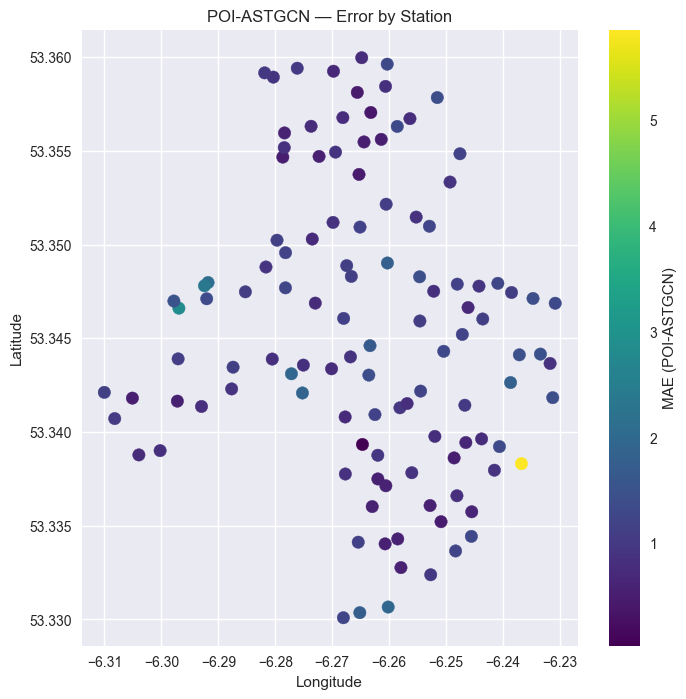

In [97]:
plt.figure(figsize=(8,8))
plt.scatter(
    stations_from_data["lon"],
    stations_from_data["lat"],
    c=mae_poi_ast,
    cmap="viridis",
    s=80
)
plt.colorbar(label="MAE (POI-ASTGCN)")
plt.title("POI-ASTGCN — Error by Station")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [98]:
best_station = np.argmin(mae_poi_ast)
worst_station = np.argmax(mae_poi_ast)

Xb, Yb = next(iter(test_loader_poi))
Xb = Xb.to(device)

with torch.no_grad():
    pred = astgcn_poi(Xb, A_norm).cpu().numpy()

Yb = Yb.numpy()
t = np.arange(pred.shape[1])

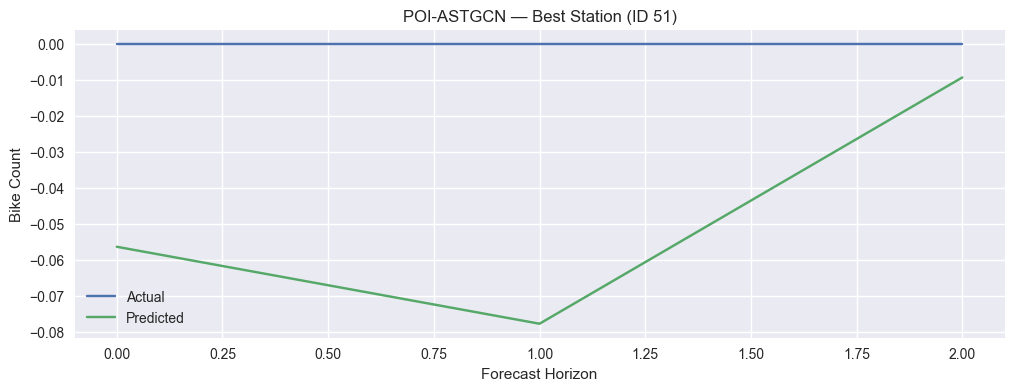

In [99]:
plt.figure(figsize=(12,4))
plt.plot(t, Yb[0,:,best_station], label="Actual")
plt.plot(t, pred[0,:,best_station], label="Predicted")
plt.title(f"POI-ASTGCN — Best Station (ID {station_list[best_station]})")
plt.xlabel("Forecast Horizon")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

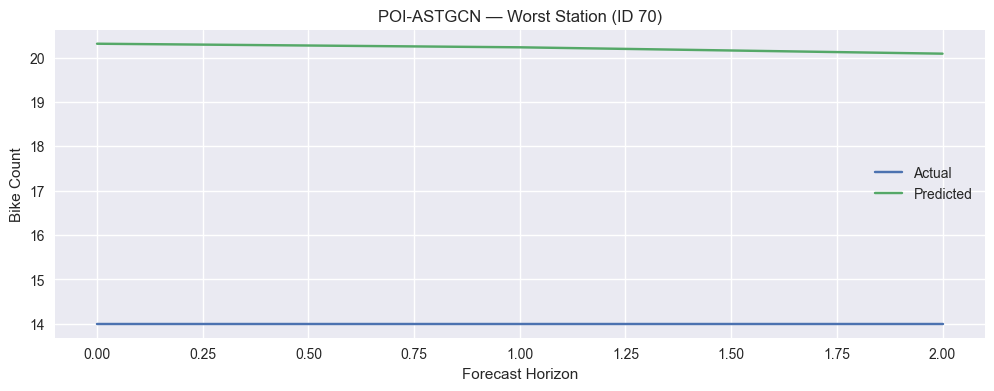

In [100]:
plt.figure(figsize=(12,4))
plt.plot(t, Yb[0,:,worst_station], label="Actual")
plt.plot(t, pred[0,:,worst_station], label="Predicted")
plt.title(f"POI-ASTGCN — Worst Station (ID {station_list[worst_station]})")
plt.xlabel("Forecast Horizon")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

In [101]:
poi_ast_station_results = (
    pd.DataFrame({
        "station_id": station_list,
        "MAE": mae_poi_ast,
        "RMSE": rmse_poi_ast
    })
    .sort_values("MAE")
)

poi_ast_station_results.head()

,station_id,MAE,RMSE
49,51,0.029567,0.033205
59,61,0.378142,0.424144
77,79,0.440768,0.486541
29,30,0.442081,0.494808
86,89,0.462530,0.506645


In [102]:
print("POI-STGCN mean station MAE:", mae_poi.mean())
print("POI-ASTGCN mean station MAE:", mae_poi_ast.mean())
print("Mean MAE gain (ST - AST):", (mae_poi - mae_poi_ast).mean())

POI-STGCN mean station MAE: 1.242466501834711
POI-ASTGCN mean station MAE: 1.0639090381735352
Mean MAE gain (ST - AST): 0.17855746366117559


In [103]:
delta_mae = mae_poi - mae_poi_ast  # positive = AST better
pct_improve = (delta_mae / (mae_poi + 1e-6)) * 100

In [104]:
print("Stations improved by attention (delta>0):", (delta_mae > 0).sum(), "/", len(delta_mae))
print("Stations worse with attention (delta<0):", (delta_mae < 0).sum(), "/", len(delta_mae))

Stations improved by attention (delta>0): 103 / 115
Stations worse with attention (delta<0): 12 / 115


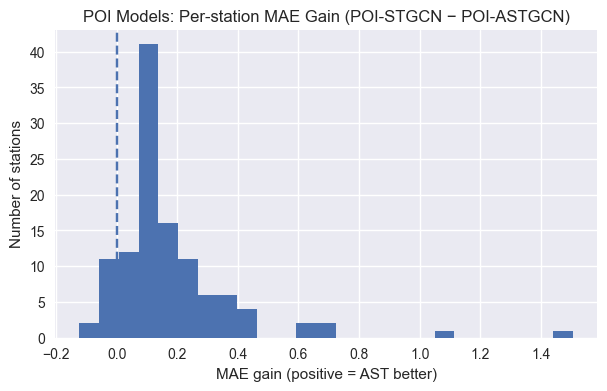

In [105]:
plt.figure(figsize=(7,4))
plt.hist(delta_mae, bins=25)
plt.axvline(0, linestyle="--")
plt.title("POI Models: Per-station MAE Gain (POI-STGCN − POI-ASTGCN)")
plt.xlabel("MAE gain (positive = AST better)")
plt.ylabel("Number of stations")
plt.show()

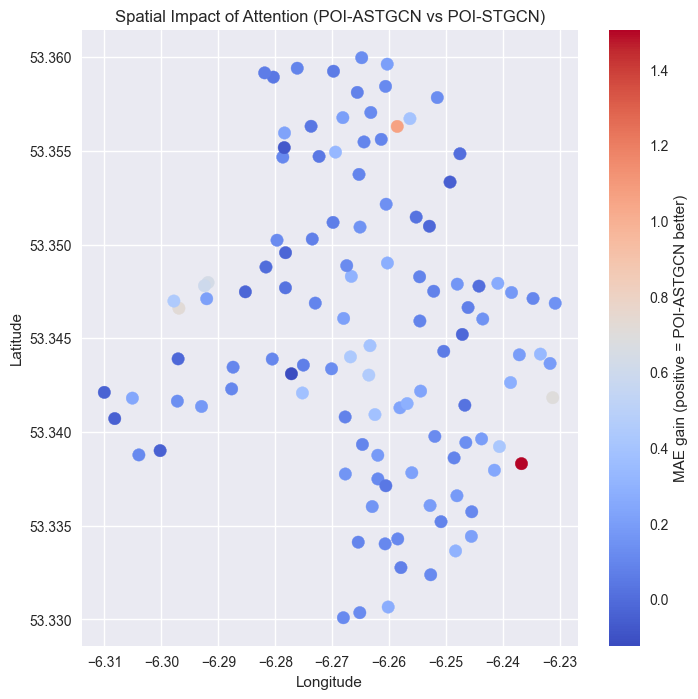

In [106]:
stations_from_data["poi_attention_gain"] = delta_mae

plt.figure(figsize=(8,8))
plt.scatter(
    stations_from_data["lon"],
    stations_from_data["lat"],
    c=stations_from_data["poi_attention_gain"],
    cmap="coolwarm",
    s=80
)
plt.colorbar(label="MAE gain (positive = POI-ASTGCN better)")
plt.title("Spatial Impact of Attention (POI-ASTGCN vs POI-STGCN)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [107]:
gain_df = pd.DataFrame({
    "station_id": station_list,
    "POI_STGCN_MAE": mae_poi,
    "POI_ASTGCN_MAE": mae_poi_ast,
    "MAE_gain": delta_mae,
    "pct_improve": pct_improve
}).sort_values("MAE_gain", ascending=False)

# 1) Graph degree (exclude self-loop)
A_bin = (A > 0).astype(int)
graph_degree = A_bin.sum(axis=1) - 1  # (N,)

# 2) Simple volatility metric from raw availability
#    average absolute change per step
volatility = np.mean(np.abs(np.diff(data, axis=0)), axis=0)  # (N,)

# 3) POI profile per station (counts)
poi_profile = station_h3_features[["station_id"] + poi_cols].copy()
poi_profile["poi_total"] = poi_profile[poi_cols].sum(axis=1)
poi_profile["poi_dominant"] = poi_profile[poi_cols].idxmax(axis=1)
poi_profile.loc[poi_profile["poi_total"] == 0, "poi_dominant"] = "none"

# 4) Location
coord_df = (
    stations_from_data.set_index("station_id")
    .loc[station_list][["lat", "lon"]]
    .reset_index()
)

# merge all
gain_props = (
    gain_df.merge(coord_df, on="station_id", how="left")
          .merge(poi_profile, on="station_id", how="left")
)

# merge graph_degree + volatility by station_id
node_stats = pd.DataFrame({
    "station_id": station_list,
    "graph_degree": graph_degree,
    "volatility": volatility
})

gain_props = gain_props.merge(node_stats, on="station_id", how="left")


cols_show = ["station_id", "MAE_gain", "pct_improve", "poi_dominant", "poi_total", "graph_degree", "volatility", "lat", "lon"]

print("Top 10 stations where attention helps most (with POIs) + properties:")
display(gain_props.sort_values("MAE_gain", ascending=False)[cols_show].head(10))

print("Top 10 stations where attention hurts most (with POIs) + properties:")
display(gain_props.sort_values("MAE_gain", ascending=True)[cols_show].head(10))

# quick grouped view: do some POI types benefit more?
group_summary = (
    gain_props.groupby("poi_dominant")["MAE_gain"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("MAE_gain grouped by dominant POI type:")
display(group_summary)

Top 10 stations where attention helps most (with POIs) + properties:


,station_id,MAE_gain,pct_improve,poi_dominant,poi_total,graph_degree,volatility,lat,lon
0,70,1.504841,20.448124,other,37,4,0.200948,53.338310,-6.236779
1,28,1.061775,44.876370,other,46,8,0.628269,53.356300,-6.258586
2,93,0.722560,20.436148,other,27,5,0.326939,53.346603,-6.296924
3,91,0.698071,33.609430,other,10,4,0.635553,53.341830,-6.231291
4,86,0.637995,23.176273,other,213,5,0.546270,53.347973,-6.291804
5,92,0.601595,20.352397,other,213,5,0.504463,53.347800,-6.292432
6,9,0.454478,24.566036,other,292,10,0.780855,53.343033,-6.263578
7,94,0.444474,22.529169,other,27,5,0.173453,53.346985,-6.297804
8,10,0.433637,33.041948,other,292,7,0.456387,53.344006,-6.266802
9,58,0.418852,23.988278,other,48,6,0.770100,53.339220,-6.240642


Top 10 stations where attention hurts most (with POIs) + properties:


,station_id,MAE_gain,pct_improve,poi_dominant,poi_total,graph_degree,volatility,lat,lon
114,72,-0.122721,-6.749228,shopping,79,4,0.366061,53.343105,-6.277167
113,104,-0.077768,-10.025640,other,56,7,0.079971,53.355170,-6.278424
112,109,-0.046641,-5.479188,other,26,3,0.314042,53.353333,-6.249319
111,84,-0.045770,-5.771050,other,12,3,0.253010,53.339005,-6.300217
110,83,-0.040328,-4.044143,other,42,3,0.347507,53.340714,-6.308191
109,97,-0.036429,-3.246071,other,42,2,0.462300,53.342113,-6.310015
108,42,-0.025850,-2.238893,other,39,5,0.489338,53.349564,-6.278198
107,87,-0.022676,-2.171511,other,56,7,0.366075,53.347477,-6.285250
106,64,-0.015683,-1.347417,other,58,7,0.526145,53.345203,-6.247163
105,38,-0.015529,-1.258492,other,131,5,0.596146,53.350975,-6.252940


MAE_gain grouped by dominant POI type:


,count,mean,median
poi_dominant,,,
food_drink,1,0.397985,0.397985
other,104,0.177346,0.117983
shopping,10,0.169216,0.119270


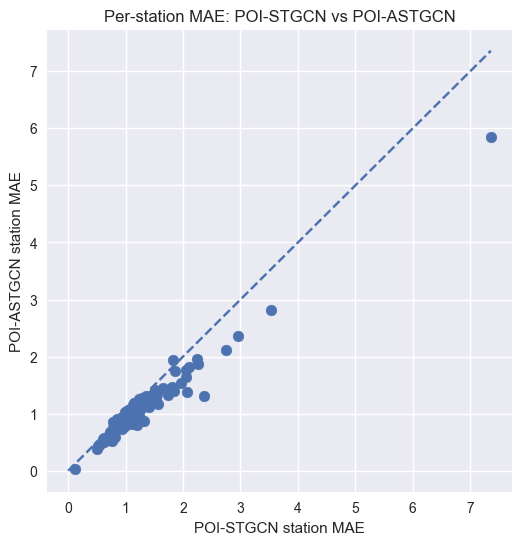

In [108]:
plt.figure(figsize=(6,6))
plt.scatter(mae_poi, mae_poi_ast, s=60)
mx = max(mae_poi.max(), mae_poi_ast.max())
plt.plot([0, mx], [0, mx], linestyle="--")  # y=x line

plt.xlabel("POI-STGCN station MAE")
plt.ylabel("POI-ASTGCN station MAE")
plt.title("Per-station MAE: POI-STGCN vs POI-ASTGCN")
plt.show()

In [109]:
stgcn_model = STGCN(
    num_nodes=A.shape[0],
    in_channels=X_train.shape[-1],
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
).to(device)

stgcn_model.load_state_dict(
    torch.load("stgcn_best.pt", map_location=device, weights_only=True)
)
stgcn_model.eval()

STGCN(
  (block1): STConvBlock(
    (temp1): TemporalConv(
      (conv): Conv2d(5, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (graph_conv): GraphConv(
      (linear): Linear(in_features=16, out_features=16, bias=True)
    )
    (temp2): TemporalConv(
      (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (residual): Conv2d(5, 32, kernel_size=(1, 1), stride=(1, 1))
    (relu): ReLU()
  )
  (block2): STConvBlock(
    (temp1): TemporalConv(
      (conv): Conv2d(32, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (graph_conv): GraphConv(
      (linear): Linear(in_features=16, out_features=16, bias=True)
    )
    (temp2): TemporalConv(
      (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (relu): ReLU()
  )
  (temp_out): TemporalConv(
    (conv): Conv2d(32, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
  )
  (proj): Linear(in_features=32, out_features=1, bias=True)
)

In [110]:
astgcn_model = ASTGCN(
    num_nodes=A.shape[0],
    in_channels=X_train.shape[-1],
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
).to(device)

astgcn_model.load_state_dict(
    torch.load("astgcn_best.pt", map_location=device, weights_only=True)
)
astgcn_model.eval()

ASTGCN(
  (block1): ASTBlock(
    (st_block): STConvBlock(
      (temp1): TemporalConv(
        (conv): Conv2d(5, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (graph_conv): GraphConv(
        (linear): Linear(in_features=16, out_features=16, bias=True)
      )
      (temp2): TemporalConv(
        (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (residual): Conv2d(5, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (tattn): TemporalAttention(
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
      )
    )
    (relu): ReLU()
  )
  (block2): ASTBlock(
    (st_block): STConvBlock(
      (temp1): TemporalConv(
        (conv): Conv2d(32, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (graph_conv): GraphConv(
        (linear): Linear(in_features=16, out_features=16, bias=True)
      )
      (temp2): TemporalCo

In [111]:
stgcn_poi = STGCN(
    num_nodes=A.shape[0],
    in_channels=X_train_poi.shape[-1],
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
).to(device)

stgcn_poi.load_state_dict(
    torch.load("stgcn_poi_best.pt", map_location=device, weights_only=True)
)
stgcn_poi.eval()

STGCN(
  (block1): STConvBlock(
    (temp1): TemporalConv(
      (conv): Conv2d(11, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (graph_conv): GraphConv(
      (linear): Linear(in_features=16, out_features=16, bias=True)
    )
    (temp2): TemporalConv(
      (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (residual): Conv2d(11, 32, kernel_size=(1, 1), stride=(1, 1))
    (relu): ReLU()
  )
  (block2): STConvBlock(
    (temp1): TemporalConv(
      (conv): Conv2d(32, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (graph_conv): GraphConv(
      (linear): Linear(in_features=16, out_features=16, bias=True)
    )
    (temp2): TemporalConv(
      (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
    )
    (relu): ReLU()
  )
  (temp_out): TemporalConv(
    (conv): Conv2d(32, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
  )
  (proj): Linear(in_features=32, out_features=1, bias=True)
)

In [112]:
astgcn_poi = ASTGCN(
    num_nodes=A.shape[0],
    in_channels=X_train_poi.shape[-1],
    spatial_channels=16,
    out_channels=32,
    T_in=18,
    T_out=3,
).to(device)

astgcn_poi.load_state_dict(
    torch.load("astgcn_poi_best.pt", map_location=device, weights_only=True)
)
astgcn_poi.eval()

ASTGCN(
  (block1): ASTBlock(
    (st_block): STConvBlock(
      (temp1): TemporalConv(
        (conv): Conv2d(11, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (graph_conv): GraphConv(
        (linear): Linear(in_features=16, out_features=16, bias=True)
      )
      (temp2): TemporalConv(
        (conv): Conv2d(16, 32, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (residual): Conv2d(11, 32, kernel_size=(1, 1), stride=(1, 1))
      (relu): ReLU()
    )
    (tattn): TemporalAttention(
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
      )
    )
    (relu): ReLU()
  )
  (block2): ASTBlock(
    (st_block): STConvBlock(
      (temp1): TemporalConv(
        (conv): Conv2d(32, 16, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0))
      )
      (graph_conv): GraphConv(
        (linear): Linear(in_features=16, out_features=16, bias=True)
      )
      (temp2): Temporal

In [113]:
criterion = nn.L1Loss()

def compute_test_mae(model, loader):
    total = 0.0
    with torch.no_grad():
        for Xb, Yb in loader:
            Xb = Xb.to(device)
            Yb = Yb.to(device)
            pred = model(Xb, A_norm)
            total += criterion(pred, Yb).item() * Xb.size(0)
    return total / len(loader.dataset)

In [114]:
stgcn_mae = compute_test_mae(stgcn_model, test_loader)
astgcn_mae = compute_test_mae(astgcn_model, test_loader)

poi_stgcn_mae = compute_test_mae(stgcn_poi, test_loader_poi)
poi_astgcn_mae = compute_test_mae(astgcn_poi, test_loader_poi)

print("ST-GCN MAE:", stgcn_mae)
print("AST-GCN MAE:", astgcn_mae)
print("POI-STGCN MAE:", poi_stgcn_mae)
print("POI-ASTGCN MAE:", poi_astgcn_mae)

ST-GCN MAE: 3.8841908473060243
AST-GCN MAE: 3.0827825402759372
POI-STGCN MAE: 1.2424665478297643
POI-ASTGCN MAE: 1.063909074351901


In [115]:
summary_df = pd.DataFrame({
    "Model": [
        "ST-GCN",
        "AST-GCN",
        "POI-STGCN",
        "POI-ASTGCN"
    ],
    "Test MAE": [
        stgcn_mae,
        astgcn_mae,
        poi_stgcn_mae,
        poi_astgcn_mae
    ]
})

summary_df

,Model,Test MAE
0,ST-GCN,3.884191
1,AST-GCN,3.082783
2,POI-STGCN,1.242467
3,POI-ASTGCN,1.063909


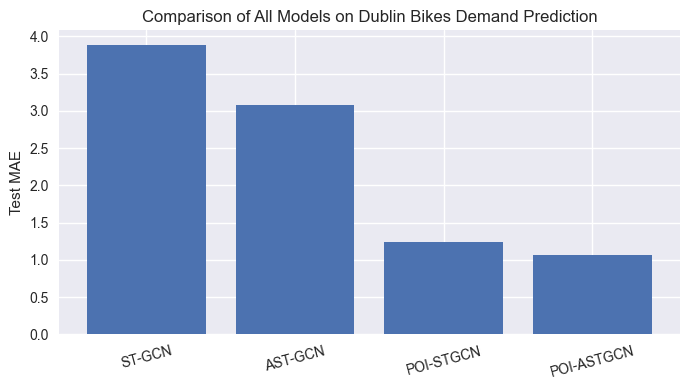

In [116]:
plt.figure(figsize=(7,4))
plt.bar(summary_df["Model"], summary_df["Test MAE"])
plt.ylabel("Test MAE")
plt.title("Comparison of All Models on Dublin Bikes Demand Prediction")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

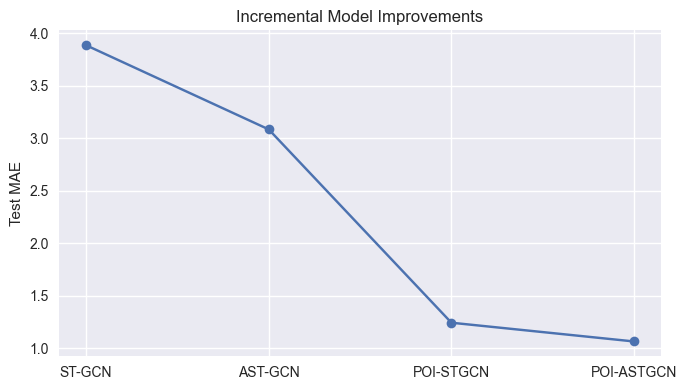

In [117]:
plt.figure(figsize=(7,4))
plt.plot(summary_df["Model"], summary_df["Test MAE"], marker="o")
plt.ylabel("Test MAE")
plt.title("Incremental Model Improvements")
plt.grid(True)
plt.tight_layout()
plt.show()

In [118]:
!pip install captum

In [119]:
from captum.attr import IntegratedGradients
import numpy as np
import torch
import matplotlib.pyplot as plt

In [120]:
def pick_representative_sample(model, loader, name):
    model.eval()
    xb, yb = next(iter(loader))
    xb = xb.to(device)
    yb_np = yb.detach().cpu().numpy()

    with torch.no_grad():
        pred = model(xb, A_norm).detach().cpu().numpy()

    per_sample = np.mean(np.abs(pred - yb_np), axis=(1, 2))
    mean_mae = float(per_sample.mean())
    idx = int(np.argmin(np.abs(per_sample - mean_mae)))

    print(f"[{name}] representative idx={idx}, "
          f"sample_MAE={per_sample[idx]:.4f}, batch_mean={mean_mae:.4f}")

    return xb[idx:idx+1].detach().clone().requires_grad_(True)

In [121]:
def explain_with_ig(model, x_in, name,
                    target_station_idx=0,
                    target_horizon_idx=0,
                    top_k=10,
                    feature_names=None):
    """
    Returns:
      score_ts: (T_in, N) time-station importance (sum over features)
      attr_np:  (T_in, N, F) raw IG attributions for features
    """
    model.eval()

    # x_in expected shape: (1, T_in, N, F)
    T_in = x_in.shape[1]
    N    = x_in.shape[2]
    Fdim = x_in.shape[3]

    def forward_scalar(x):
        out = model(x, A_norm)
        # out: (B, T_out, N)
        return out[:, target_horizon_idx, target_station_idx]

    ig = IntegratedGradients(forward_scalar)

    # baseline = zero input
    baseline = torch.zeros_like(x_in)

    attr = ig.attribute(x_in, baselines=baseline, n_steps=64)  # (1, T_in, N, F)
    attr_np = attr.detach().cpu().numpy()[0]                   # (T_in, N, F)

    # time-station importance (sum over features)
    score_ts = np.abs(attr_np).sum(axis=-1)                    # (T_in, N)

    # feature importance (sum over time + stations)
    feat_imp = np.abs(attr_np).sum(axis=(0, 1))                # (F,)

    # temporal + spatial importance (optional but useful)
    time_imp = score_ts.sum(axis=1)                            # (T_in,)
    station_imp = score_ts.sum(axis=0)                         # (N,)

    flat = score_ts.reshape(-1)
    top = flat.argsort()[-top_k:][::-1]

    print(f"\n--- IG Explainability: {name} ---")
    print(f"Target: horizon={target_horizon_idx}, station_id={station_list[target_station_idx]}")

    for k, idx in enumerate(top, 1):
        t = idx // N
        s = idx % N
        rel = (T_in - 1) - t
        print(f"{k:02d}. t-{rel:02d}, station_id={station_list[s]}, score={flat[idx]:.6f}")

    # Feature importance printout (this is what your supervisor wants)
    if feature_names is None:
        feature_names = [f"F{i}" for i in range(Fdim)]

    feat_imp_norm = feat_imp / (feat_imp.sum() + 1e-12)

    print("\nTop feature importances (normalized):")
    order = np.argsort(feat_imp_norm)[::-1]
    for i in order[:min(10, len(order))]:
        print(f"  {feature_names[i]}: {feat_imp_norm[i]:.4f}")

    return score_ts, attr_np

In [122]:
target_station_idx = 0
target_horizon_idx = 0

# ST-GCN
x_rep = pick_representative_sample(stgcn, test_loader, "ST-GCN")
score_st, _ = explain_with_ig(
    stgcn, x_rep, "ST-GCN",
    target_station_idx, target_horizon_idx
)

# AST-GCN
x_rep = pick_representative_sample(astgcn, test_loader, "AST-GCN")
score_ast, _ = explain_with_ig(
    astgcn, x_rep, "AST-GCN",
    target_station_idx, target_horizon_idx
)

# POI ST-GCN
x_rep = pick_representative_sample(stgcn_poi, test_loader_poi, "POI ST-GCN")
score_poi_st, attr_poi_st = explain_with_ig(
    stgcn_poi, x_rep, "POI ST-GCN",
    target_station_idx, target_horizon_idx
)

# POI AST-GCN
x_rep = pick_representative_sample(astgcn_poi, test_loader_poi, "POI AST-GCN")
score_poi_ast, _ = explain_with_ig(
    astgcn_poi, x_rep, "POI AST-GCN",
    target_station_idx, target_horizon_idx
)

[ST-GCN] representative idx=54, sample_MAE=3.7048, batch_mean=3.7149

--- IG Explainability: ST-GCN ---
Target: horizon=0, station_id=1
01. t-01, station_id=1, score=2.189276
02. t-03, station_id=1, score=1.429307
03. t-01, station_id=71, score=1.270384
04. t-00, station_id=27, score=1.214331
05. t-00, station_id=10, score=1.088243
06. t-00, station_id=71, score=1.066013
07. t-05, station_id=27, score=1.024942
08. t-01, station_id=27, score=1.003753
09. t-01, station_id=10, score=1.002132
10. t-02, station_id=1, score=0.976150

Top feature importances (normalized):
  F0: 0.4713
  F2: 0.3029
  F4: 0.0896
  F1: 0.0721
  F3: 0.0641
[AST-GCN] representative idx=0, sample_MAE=2.9734, batch_mean=2.9727

--- IG Explainability: AST-GCN ---
Target: horizon=0, station_id=1
01. t-00, station_id=1, score=10.826447
02. t-03, station_id=1, score=0.747869
03. t-01, station_id=1, score=0.536550
04. t-00, station_id=9, score=0.448628
05. t-02, station_id=1, score=0.438568
06. t-00, station_id=52, score

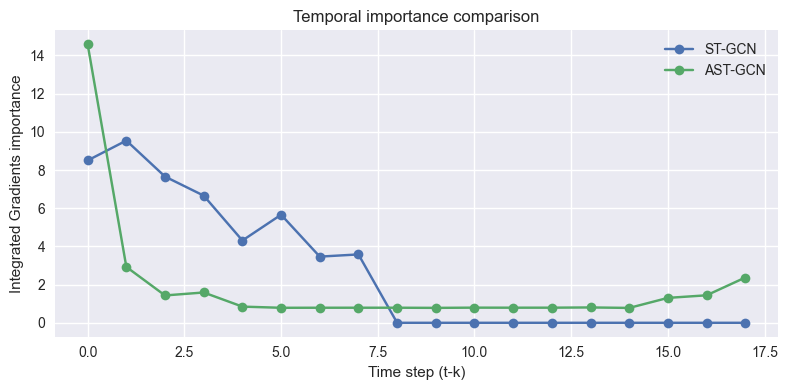

In [123]:
# Temporal Importance Comparision
time_imp_st  = score_st.sum(axis=1)
time_imp_ast = score_ast.sum(axis=1)

T_in = score_st.shape[0]
steps = list(range(T_in-1, -1, -1))

plt.figure(figsize=(8,4))
plt.plot(steps, time_imp_st, marker="o", label="ST-GCN")
plt.plot(steps, time_imp_ast, marker="o", label="AST-GCN")
plt.xlabel("Time step (t-k)")
plt.ylabel("Integrated Gradients importance")
plt.title("Temporal importance comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

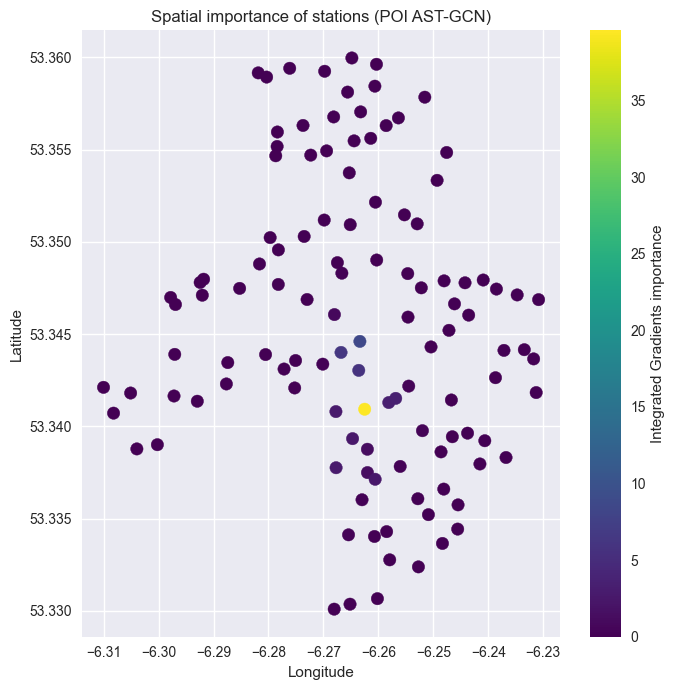

In [124]:
# Spatial Importance Map (POI AST-GCN)

station_imp = score_poi_ast.sum(axis=0)

stations_df = stations_df.copy()
stations_df["importance"] = station_imp

plt.figure(figsize=(7,7))
plt.scatter(
    stations_df["lon"],
    stations_df["lat"],
    c=stations_df["importance"],
    cmap="viridis",
    s=80
)
plt.colorbar(label="Integrated Gradients importance")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial importance of stations (POI AST-GCN)")
plt.tight_layout()
plt.show()

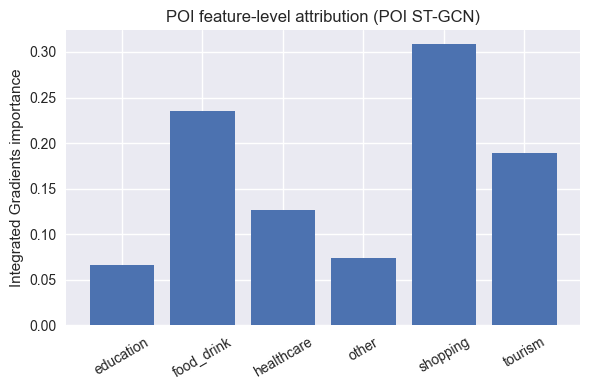

In [125]:
# POI Feature-Level Importance (POI ST-GCN)

# attr_poi_st shape: (T_in, N, F_total)
# base features = availability + time encodings
base_F = X_train.shape[-1] 

F_total = attr_poi_st.shape[-1]
F_poi = F_total - base_F

assert F_poi == len(poi_cols), f"POI dims mismatch: expected {len(poi_cols)}, got {F_poi}"

# slice only POI channels
attr_poi_only = attr_poi_st[:, :, base_F:]  # (T_in, N, F_poi)

poi_feat_importance = np.abs(attr_poi_only).sum(axis=(0, 1))  # (F_poi,)
poi_feat_importance = poi_feat_importance / (poi_feat_importance.sum() + 1e-12)

plt.figure(figsize=(6,4))
plt.bar(poi_cols, poi_feat_importance)
plt.ylabel("Integrated Gradients importance")
plt.title("POI feature-level attribution (POI ST-GCN)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [126]:
# PGExplainer-style (mask-based) edge explanation
# Goal: learn a sparse edge mask that preserves the target prediction.

def explain_edges_with_mask(model, x_in,
                            target_station_idx=0,
                            target_horizon_idx=0,
                            steps=200,
                            lr=0.1,
                            l1=0.01,
                            top_k=10):
    """
    Returns:
      mask_np: (N, N) learned edge mask in [0,1]
    Prints:
      top-k edges influencing the target station (incoming edges)
    """
    model.eval()
    x_in = x_in.detach()

    # Original target prediction
    with torch.no_grad():
        y0 = model(x_in, A_norm)[:, target_horizon_idx, target_station_idx].detach()

    # Only allow masking where an edge exists in A_bin
    A_bin = torch.tensor((A > 0).astype(np.float32), device=device)

    # Mask logits (learned)
    mask_logits = torch.zeros_like(A_norm, device=device, requires_grad=True)

    opt = torch.optim.Adam([mask_logits], lr=lr)

    for _ in range(steps):
        opt.zero_grad()

        mask = torch.sigmoid(mask_logits) * A_bin
        # enforce symmetry (undirected graph)
        mask = 0.5 * (mask + mask.T)

        A_masked = A_norm * mask

        y_hat = model(x_in, A_masked)[:, target_horizon_idx, target_station_idx]

        fidelity = torch.mean((y_hat - y0) ** 2)
        sparsity = torch.mean(mask)  # encourages fewer edges

        loss = fidelity + l1 * sparsity
        loss.backward()
        opt.step()

    mask_np = (torch.sigmoid(mask_logits).detach().cpu().numpy() * (A > 0).astype(np.float32))
    # row/col for the target station: which neighbors mattered for this station
    incoming = mask_np[:, target_station_idx]  # (N,)
    incoming[target_station_idx] = 0.0

    top_idx = np.argsort(incoming)[-top_k:][::-1]

    print("\n--- Edge explanation (mask-based) ---")
    print(f"Target station_id={station_list[target_station_idx]}, horizon={target_horizon_idx}")
    for i, n_idx in enumerate(top_idx, 1):
        if incoming[n_idx] <= 0:
            break
        print(f"{i:02d}. from station_id={station_list[n_idx]} -> {station_list[target_station_idx]}  weight={incoming[n_idx]:.4f}")

    return mask_np


# Example usage (recommended: POI AST-GCN since it's your best model)
# x_rep should be the same representative sample you already compute in Cell 122
_ = explain_edges_with_mask(
    astgcn_poi,
    x_rep,
    target_station_idx=target_station_idx,
    target_horizon_idx=target_horizon_idx,
    steps=200,
    lr=0.1,
    l1=0.01,
    top_k=10
)



--- Edge explanation (mask-based) ---
Target station_id=1, horizon=0
01. from station_id=14 -> 1  weight=0.9064
02. from station_id=10 -> 1  weight=0.8984
03. from station_id=9 -> 1  weight=0.8965
04. from station_id=27 -> 1  weight=0.8838
05. from station_id=98 -> 1  weight=0.8799
06. from station_id=52 -> 1  weight=0.8479
07. from station_id=37 -> 1  weight=0.8016
08. from station_id=71 -> 1  weight=0.0948
09. from station_id=53 -> 1  weight=0.0937
10. from station_id=17 -> 1  weight=0.0862
